# Gauss-Bonnet with geomstats

The [**Atiyah-Singer Index Theorem**](https://en.wikipedia.org/wiki/Atiyah%E2%80%93Singer_index_theorem) is my favorite theorem in mathematics. It is a deep result that relates the topology of a manifold to the geometry of its curvature, through the index of a differential operator. This theorem is the reason I decided to do a PhD in this area (see [The $S^q$-Equivariant Signature for Semi-free Actions as an Index Formula](https://link.springer.com/article/10.1007/s12220-018-0088-1)).

The first version of this theorem that I learned is the [**Gauss-Bonnet theorem**](https://en.wikipedia.org/wiki/Gauss%E2%80%93Bonnet_theorem). This version of the index theorem relates the integral of the Gaussian curvature over a closed surface to the Euler characteristic of the surface. The first proof of this result that I studied required a careful triangulation of the surface, some detailed algebra, and differential geometry of surfaces. It seemed a bit cumbersome, in my opinion. However, in the context of the index theorem, it is just a natural consequence. It is objectively beautiful.

In this notebook, I will describe how to understand the Gauss-Bonnet theorem by simply computing both sides of the equation numerically for a sphere, a torus, and an ellipsoid. We do not do this by hand, but rely on the amazing machinery developed by the [geomstats](https://github.com/geomstats/geomstats) library.

> Geomstats is a Python package for computations, statistics, machine learning and deep learning on manifolds.

This library has great abstractions of differential geometry concepts, and we can compute quantities that require derivatives, like curvatures (and higher-order tensors), with automatic differentiation.

Many of its [examples](https://geomstats.github.io/tutorials/index.html) cover the basic concepts of differential geometry and concrete real applications. Nevertheless, I think there is an opportunity to explore deeper results and examples in the context of differential geometry and pure mathematics with this library.

## The Gauss-Bonnet Theorem in a Nutshell

- **The Geometry.** Take the unit sphere. Its Gaussian curvature is constant and equal to $1$ at every point. Since the surface area of the sphere is $4\pi$, this means that the integral of the curvature over the sphere is $4\pi$.

- **The Topology.** On the other hand, we can triangulate the sphere by projecting the edges of a cube onto the sphere from its center: the sphere splits into $6$ faces with $12$ edges and $8$ vertices. For such a triangulation, we can compute the (somewhat mysterious) quantity $8 - 12 + 6 = 2$.

The Gauss-Bonnet theorem says that these two numbers are linked on every closed surface: the integral of the Gaussian curvature equals $2\pi$ times the number of vertices minus edges plus faces. For the sphere this is $4\pi = 2\pi \cdot 2$. The count, called the [Euler characteristic](https://en.wikipedia.org/wiki/Euler_characteristic), does not depend on how we cut the surface into polygons.

On other surfaces the integral of the curvature is harder to compute. The curvature changes from point to point, and computing it from the metric alone, that is, from lengths measured on the surface, needs derivatives of a parametrization up to the third order. By hand this is long and error-prone, and a numerical integral needs care where the parametrization degenerates, such as at the poles of a sphere.

In this notebook we compute both sides of the theorem numerically for a sphere, a torus, and an ellipsoid, and check that they agree. We describe each surface by a parametrization, and geomstats derives the metric and the curvature from it with the automatic differentiation of PyTorch. For the right side we take a grid on the parameter rectangle, glue its edges the way the surface closes up, and count its vertices, edges, and faces.

We keep the setting simple on purpose:

- **Closed surfaces:** Our surfaces have no boundary, so the boundary term of the general theorem does not appear.

- **One chart per surface:** We parametrize each surface over one rectangle whose edges are either glued or collapsed to points.

- **Surfaces in $\mathbb{R}^3$:** The metric of each surface is the one induced by the Euclidean space around it.

We assume you know the basic objects of the differential geometry of surfaces (first fundamental form, Gaussian curvature) at the level of [do Carmo](https://store.doverpublications.com/products/9780486806990), and that you have used automatic differentiation in PyTorch.

The main references used in this notebook are:

- **Theory:** [do Carmo](https://store.doverpublications.com/products/9780486806990) for the differential geometry of surfaces and the [Gauss-Bonnet theorem](https://en.wikipedia.org/wiki/Gauss%E2%80%93Bonnet_theorem).

- **Software:** [geomstats](https://github.com/geomstats/geomstats) ([Miolane et al.](https://jmlr.org/papers/v21/19-027.html)), which computes the curvature of a parametrized surface with automatic differentiation.

- **Quadrature:** [Trefethen and Weideman](https://doi.org/10.1137/130932132) on the trapezoidal rule for periodic integrands.



## Prepare Notebook

We select the backend of geomstats with the `GEOMSTATS_BACKEND` environment variable before the first import, because geomstats reads it only then. We also load the jaxtyping extension, so that beartype checks the shapes in our type annotations at run time (see *Base Class*).

In [1]:
%env GEOMSTATS_BACKEND=pytorch

env: GEOMSTATS_BACKEND=pytorch


In [2]:
from abc import ABC, abstractmethod
from collections.abc import Callable
from typing import NamedTuple

import arviz as az
import geomstats.backend as gs
import matplotlib.pyplot as plt
import torch
from geomstats.geometry.base import ImmersedSet
from geomstats.geometry.euclidean import Euclidean
from jaxtyping import Float, Int
from matplotlib.colors import CenteredNorm
from numpy.polynomial.legendre import leggauss
from torch import Tensor

seed: int = 42
rng: torch.Generator = torch.Generator().manual_seed(seed)

HDI_PROB = 0.94

az.style.use("arviz-darkgrid")
az.rcParams["stats.ci_kind"] = "hdi"
az.rcParams["stats.ci_prob"] = HDI_PROB
plt.rcParams["figure.figsize"] = [10, 6]
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.facecolor"] = "white"

%load_ext autoreload
%autoreload 2
%load_ext jaxtyping
%jaxtyping.typechecker beartype.beartype
%config InlineBackend.figure_format = "retina"

We check that geomstats uses the PyTorch backend and that PyTorch creates tensors in double precision, the default that geomstats sets on import. We need double precision because the checks below compare curvatures at round-off level, below $10^{-12}$, far below the round-off of single precision.

In [3]:
assert gs.__name__ == "geomstats.pytorch"
assert torch.get_default_dtype() == torch.float64

Now that we compute in double precision, we can state the theorem.

## The Gauss-Bonnet Theorem

Let $M$ be a compact, oriented, two-dimensional Riemannian manifold with a smooth (possibly empty) boundary $\partial M$. We use the following notation:

- $K$ is the **Gaussian curvature** of $M$ and $dA$ is its **area element**.
- $k_g$ is the **geodesic curvature** of the boundary and $ds$ is the arc length along it.
- $\chi(M) = V - E + F$ is the **Euler characteristic** of $M$, where $V$, $E$, and $F$ are the numbers of vertices, edges, and faces of any polygonal decomposition of $M$ (see [Euler characteristic](https://en.wikipedia.org/wiki/Euler_characteristic)).

With this notation, the [Gauss-Bonnet theorem](https://en.wikipedia.org/wiki/Gauss%E2%80%93Bonnet_theorem) states that

$$
\int_M K \, dA + \int_{\partial M} k_g \, ds = 2 \pi \chi(M).
$$

When $M$ is closed, that is, compact and without boundary, the boundary term is absent:

$$
\int_M K \, dA = 2 \pi \chi(M).
$$

This is the case we treat here. The left side depends only on the metric of the surface, which measures lengths inside it. The right side depends only on its topology.

Why does the right side not depend on the polygonal decomposition? The Euler characteristic equals the alternating sum of the [Betti numbers](https://en.wikipedia.org/wiki/Betti_number) $b_k$ of $M$, the ranks of its singular homology groups (see the section "Betti number alternative" of [Euler characteristic](https://en.wikipedia.org/wiki/Euler_characteristic)). On a surface, $b_k = 0$ for $k > 2$, so

$$
\chi(M) = b_0 - b_1 + b_2.
$$

Homology is a topological invariant (see the section "Homotopy invariance" of the same article). Hence $\chi$ is a topological invariant too, and every polygonal decomposition of $M$ gives the same value of $V - E + F$.

Here is an important observation about the implications of the Gauss-Bonnet theorem: when we deform a surface smoothly, the values of $K$ and $dA$ at each point change, but the integral of $K \, dA$ stays the same.

**Examples.**

- For a closed orientable surface, the Euler characteristic is $\chi = 2 - 2 \, \text{genus}$, where the genus is the number of holes (see the section "Relations to other invariants" of [Euler characteristic](https://en.wikipedia.org/wiki/Euler_characteristic)). The sphere has the Betti numbers $1, 0, 1$ and genus $0$, so $\chi = 2$. The torus has the Betti numbers $1, 2, 1$ and genus $1$, so $\chi = 0$.

- A sphere of radius $\rho$ has constant curvature $K = 1 / \rho^2$ and area $4 \pi \rho^2$, so its total curvature, the integral of $K \, dA$, is $4 \pi = 2 \pi \cdot 2$ for every radius. The curvature of a torus is positive on the outer half and negative on the inner half, and the two parts cancel.

To compute the left side on other surfaces, we need $K$ in the coordinates of a parametrization.

## Curvature in Coordinates

We describe a surface by an **immersion** $f: U \to \mathbb{R}^3$ of a parameter domain $U \subset \mathbb{R}^2$, written $(u, v) \mapsto f(u, v)$. We write $\partial_i$ for the partial derivative with respect to the coordinate $i \in \{u, v\}$, and we sum over repeated indices.

### Induced Metric

The **induced metric**, also called the pullback metric or the first fundamental form, is the matrix of inner products of the first derivatives of $f$,

$$
g_{ij} = \langle \partial_i f, \partial_j f \rangle.
$$

It measures lengths inside the surface: a small step $(du, dv)$ in the parameters moves the point $f(u, v)$ by a distance $ds$ with

$$
ds^2 = g_{uu} \, du^2 + 2 g_{uv} \, du \, dv + g_{vv} \, dv^2.
$$

The area element is $dA = \sqrt{\det g} \, du \, dv$, with $\det g = g_{uu} g_{vv} - g_{uv}^2$. We write $g^{ij}$ for the entries of the inverse matrix $g^{-1}$.

Let's work a simple example. The sphere of radius $\rho$ uses as its coordinates $(u, v) = (\theta, \varphi)$ the polar angle and the azimuth:

$$
f(\theta, \varphi) = \rho \left( \sin\theta \cos\varphi, \; \sin\theta \sin\varphi, \; \cos\theta \right).
$$

Its first derivatives are orthogonal, so

$$
g = \begin{pmatrix} \rho^2 & 0 \\ 0 & \rho^2 \sin^2\theta \end{pmatrix}, \qquad dA = \rho^2 \sin\theta \, d\theta \, d\varphi.
$$

A step in $\varphi$ is short near the poles, and at a pole $\det g = 0$. Keep this in mind for *Total Curvature*.

### Gaussian Curvature

The metric tells us how far apart points are. The curvature tells us how the surface bends. At each point, the surface has a tangent plane and a unit normal

$$
N = \frac{\partial_u f \times \partial_v f}{\| \partial_u f \times \partial_v f \|}.
$$

Cut the surface with a plane that contains $N$. The cut is a curve, called a **normal section**. Its curvature is one over the radius of the circle that fits it best, with a positive sign if the curve turns toward $N$.

As the plane rotates around $N$, this curvature changes. Its largest and smallest values are the **principal curvatures** $\kappa_1$ and $\kappa_2$ (see [Principal curvature](https://en.wikipedia.org/wiki/Principal_curvature)), and the **Gaussian curvature** is their product (see [Gaussian curvature](https://en.wikipedia.org/wiki/Gaussian_curvature)):

$$
K = \kappa_1 \kappa_2.
$$

The sign of $K$ tells us the shape of the surface near the point:

- **Sphere of radius $\rho$:** Every normal section is a great circle of radius $\rho$, so both principal curvatures have size $1 / \rho$, with the sign set by the choice of $N$, and $K = 1 / \rho^2 > 0$.
- **Cylinder:** The section around the cylinder is a circle, and the section along it is a straight line, so one principal curvature is $0$ and $K = 0$.
- **Saddle:** The surface bends toward $N$ in one direction and away from it in the other, so $K < 0$. The inner half of a torus looks like this.

If we flip $N$, both principal curvatures change sign, so $K$ does not depend on the choice of the normal.

To compute $K$ in coordinates, we look at the second derivatives of $f$. Their component along $N$ measures how fast the surface leaves its tangent plane. This is the **second fundamental form**

$$
h_{ij} = \langle \partial_i \partial_j f, N \rangle.
$$

For a tangent direction with coordinates $w = (w^u, w^v)$, write $g(w, w) = g_{ij} w^i w^j$ and $h(w, w) = h_{ij} w^i w^j$. The normal curvature in this direction is the following ratio (see Chapter $3$ of [do Carmo](https://store.doverpublications.com/products/9780486806990)):

$$
\frac{h(w, w)}{g(w, w)}.
$$

The ratio does not change when we scale $w$, so it is enough to look at the directions of unit length on the surface, that is, with $g(w, w) = 1$. The principal curvatures are then the largest and the smallest values of $h(w, w)$ over these directions.

To find them, we use a [Lagrange multiplier](https://en.wikipedia.org/wiki/Lagrange_multiplier) $\kappa$ for the constraint $g(w, w) = 1$. The derivative of $h(w, w) - \kappa \left( g(w, w) - 1 \right)$ with respect to $w^i$ is $2 h_{ij} w^j - 2 \kappa \, g_{ij} w^j$. It vanishes at the largest and at the smallest value, so there

$$
h_{ij} w^j = \kappa \, g_{ij} w^j, \quad \text{or, as matrices,} \quad h w = \kappa \, g w.
$$

If we multiply both sides by $g^{-1}$, we get $g^{-1} h \, w = \kappa \, w$. So each of the two extreme directions $w$ is an eigenvector of the $2 \times 2$ matrix $g^{-1} h$, and the multiplier $\kappa$ is its eigenvalue.

The eigenvalue is also the normal curvature in that direction. If we multiply $h_{ij} w^j = \kappa \, g_{ij} w^j$ by $w^i$ and sum over $i$, we get $h(w, w) = \kappa \, g(w, w) = \kappa$. Hence the two eigenvalues of $g^{-1} h$ are the principal curvatures $\kappa_1$ and $\kappa_2$.

Note that when the tangent vectors $\partial_u f$ and $\partial_v f$ are orthonormal, $g$ is the identity and the principal curvatures are the eigenvalues of $h$ itself (see [Principal curvature](https://en.wikipedia.org/wiki/Principal_curvature)). The factor $g^{-1}$ accounts for coordinates whose tangent vectors are not orthonormal, such as the polar angle and the azimuth of the sphere.

The determinant of a matrix is the product of its eigenvalues, so

$$
K = \kappa_1 \kappa_2 = \det(g^{-1} h) = \frac{\det h}{\det g}.
$$

**Example.**

Let's go back to the sphere. There $N = f / \rho$ points outward, and the second derivatives of $f$ give

$$
h_{\theta\theta} = \langle -f, N \rangle = -\rho, \qquad h_{\theta\varphi} = 0, \qquad h_{\varphi\varphi} = -\rho \sin^2\theta,
$$

so $h = -g / \rho$. Then $g^{-1} h$ is $-1 / \rho$ times the identity, $\kappa_1 = \kappa_2 = -1 / \rho$, and $K = 1 / \rho^2$. The minus sign says that the sphere bends away from its outward normal, and it cancels in the product.

We call this the **extrinsic** route to $K$, because it uses the normal $N$, which points out of the surface into $\mathbb{R}^3$. It needs the first and the second derivatives of $f$.

### Theorema Egregium

The definition of $K$ uses the space around the surface. Yet Gauss's [Theorema Egregium](https://en.wikipedia.org/wiki/Theorema_Egregium) says that $K$ depends only on $g$ and its derivatives. Its Wikipedia article states the theorem and its consequence for bending as follows:

> The theorem says that Gaussian curvature can be determined entirely by measuring angles, distances and their rates of change on a surface, without reference to the particular manner in which the surface is embedded in the ambient 3-dimensional Euclidean space. In other words, the Gaussian curvature of a surface does not change if one bends the surface without stretching it. Thus the Gaussian curvature is an intrinsic invariant of a surface.

Recall the cylinder from above. We can roll it out of a flat sheet of paper without stretching, and indeed both have $K = 0$. A sphere has $K > 0$, so no piece of it can be flattened without stretching, and no flat map of the Earth keeps all distances (see [Gaussian curvature](https://en.wikipedia.org/wiki/Gaussian_curvature)).

How can a quantity that we defined with $N$ depend on $g$ alone? We now work backwards from $h$ to $g$.

### Intrinsic Route

We connect $K$ to the metric in three steps.

First, we split the second derivatives of $f$ into a part in the tangent plane and a part along $N$. This is the Gauss formula (see [Gauss-Codazzi equations](https://en.wikipedia.org/wiki/Gauss%E2%80%93Codazzi_equations)):

$$
\partial_i \partial_j f = \Gamma^k_{ij} \, \partial_k f + h_{ij} \, N.
$$

The normal part is $h$. The tangent part defines the **Christoffel symbols** $\Gamma^k_{ij}$, which say how the tangent vectors $\partial_u f$ and $\partial_v f$ turn as we move, as seen from inside the surface. Unlike $h$, they depend only on $g$. To see this, we differentiate $g_{jl} = \langle \partial_j f, \partial_l f \rangle$:

$$
\partial_i g_{jl} = \langle \partial_i \partial_j f, \partial_l f \rangle + \langle \partial_j f, \partial_i \partial_l f \rangle.
$$

If we add $\partial_i g_{jl}$ and $\partial_j g_{il}$ and subtract $\partial_l g_{ij}$, the terms cancel in pairs because second derivatives commute. What is left is $2 \langle \partial_i \partial_j f, \partial_l f \rangle$. The Gauss formula turns this into $2 \Gamma^k_{ij} g_{kl}$, because $N$ is orthogonal to $\partial_l f$, so

$$
\Gamma^k_{ij} = \frac{1}{2} g^{kl} \left( \partial_i g_{jl} + \partial_j g_{il} - \partial_l g_{ij} \right).
$$

Next, the Christoffel symbols tell us how to differentiate a tangent vector field inside the surface. This is the covariant derivative $\nabla$ of the Levi-Civita connection, with $\nabla_{\partial_i} \partial_j = \Gamma^k_{ij} \partial_k$. In a plane, the order of two such derivatives does not matter. On a curved surface it does, and the **Riemann curvature tensor** measures the difference (see [Riemann curvature tensor](https://en.wikipedia.org/wiki/Riemann_curvature_tensor)):

$$
R(\partial_j, \partial_k) \partial_i = \nabla_{\partial_j} \nabla_{\partial_k} \partial_i - \nabla_{\partial_k} \nabla_{\partial_j} \partial_i = R^l_{ijk} \, \partial_l.
$$

If we apply the formula for $\nabla$ twice, we get the components from $\Gamma$ and its derivatives:

$$
R^l_{ijk} = \partial_j \Gamma^l_{ki} - \partial_k \Gamma^l_{ji} + \Gamma^l_{jm} \Gamma^m_{ki} - \Gamma^l_{km} \Gamma^m_{ji}.
$$

Textbooks differ in the sign and the index order of $R$, so we use the convention of geomstats throughout.

Finally, we go back to $K$. In $\mathbb{R}^3$ the order of derivatives does not matter. If we write this out for the third derivatives of $f$ with the Gauss formula and keep the tangent part, we get the **Gauss equation** $\langle R(\partial_u, \partial_v) \partial_v, \partial_u \rangle = \det h$, where the inner product is the one given by $g$ (see Chapter $4$ of [do Carmo](https://store.doverpublications.com/products/9780486806990)). With the extrinsic formula for $K$, this gives

$$
K = \frac{\det h}{\det g} = \frac{\langle R(\partial_u, \partial_v) \partial_v, \partial_u \rangle}{\det g} = \frac{g_{ul} R^l_{vuv}}{\det g}.
$$

The right side only uses $g$ and its derivatives, which is the content of the Theorema Egregium. For a surface, it is also the **sectional curvature** of the tangent plane.

This is the **intrinsic** route to $K$. It needs the third derivatives of $f$, because $R$ differentiates $\Gamma$, which differentiates $g$, which differentiates $f$. Both routes give the same $K$, and we compare them in *Curvature Checks*, after we see how geomstats computes each of these objects.

## Surfaces in geomstats

In geomstats, a parametrized manifold is an `ImmersedSet`. Its points are intrinsic coordinates $(u, v)$, and a subclass implements the method `immersion`, which is our $f$. The default metric of an `ImmersedSet` is a `PullbackMetric`, whose methods compute the objects of *Curvature in Coordinates*.

### Derivative Chain

The metric computes these objects in four steps:

1. **Metric.** `jacobian_immersion` differentiates `immersion` once, and `metric.metric_matrix` builds $g$ from the Jacobian.
2. **Christoffel symbols.** `hessian_immersion` differentiates `immersion` twice, `metric.inner_product_derivative_matrix` builds $\partial_k g_{ij}$ from the Jacobian and the Hessian, and `metric.christoffels` builds $\Gamma$.
3. **Riemann tensor.** `metric.riemann_tensor` differentiates `metric.christoffels` once more and assembles $R$.
4. **Sectional curvature.** `metric.sectional_curvature` contracts $R$ with two tangent vectors and divides by $g_{uu} g_{vv} - g_{uv}^2$.

The extrinsic route branches off after step $2$. `metric.second_fundamental_form` subtracts the tangent part $\Gamma^k_{ij} \partial_k f$ from the Hessian. By the Gauss formula, what is left is the vector $\mathrm{II}_{ij} = \partial_i \partial_j f - \Gamma^k_{ij} \partial_k f = h_{ij} N$. So geomstats returns the second fundamental form as vectors, and our $h_{ij}$ is their component along $N$.

Four conventions matter when we read these arrays:

- **Christoffel symbols:** The contravariant index comes first, so `christoffels[..., k, i, j]` is $\Gamma^k_{ij}$.
- **Riemann tensor:** The contravariant index comes last, so `riemann_tensor[..., i, j, k, l]` is $R^l_{ijk}$.
- **Hessian:** The indices of differentiation come last, so `hessian_immersion[..., :, i, j]` is the vector $\partial_i \partial_j f$.
- **Second fundamental form:** The indices of differentiation come last as well, so `second_fundamental_form[..., :, i, j]` is the vector $\mathrm{II}_{ij}$.

In the PyTorch backend, `gs.autodiff.jacobian_vec` and `gs.autodiff.hessian_vec` loop over the points and call `torch.autograd.functional.jacobian` and `torch.autograd.functional.hessian` with `create_graph=point.requires_grad` (see [`autodiff.py`](https://github.com/geomstats/geomstats/blob/1b42ec9fa9879cdfedf79cadc5adaeca300bf51b/geomstats/_backend/pytorch/autodiff.py)). PyTorch sets `requires_grad` on the inputs it differentiates, so the Jacobian and the Hessian of step $2$ keep their computational graph exactly when the outer derivative of step $3$ needs it. The loops over points also set the cost, which grows linearly with the number of points at which we evaluate $K$.

### Base Class

A parametrization covers the surface with the parameter rectangle $U = [u_{\min}, u_{\max}] \times [v_{\min}, v_{\max}]$. The rectangle has four edges, but a closed surface has no boundary.

In our parametrizations, each edge of $U$ either meets the opposite edge on the surface or shrinks to a single point. We call this rule for one parameter direction its **closure**:

- **Periodic:** The parameter is an angle that comes back to its start after a full turn. The two opposite edges map to the same curve on the surface, and we say that they are glued. Both angles of the torus and the azimuth $\varphi$ of the sphere are periodic.
- **Pole:** Each end of the parameter range maps to a single point, so each of the two edges collapses to its own point. The polar angle $\theta$ of the sphere is of this type: every point with $\theta = 0$ is the north pole, whatever the value of $\varphi$.

We need the closures twice. The quadrature rule of the left side depends on them (see *Total Curvature*), and so does the glued grid of the right side (see *Euler Characteristic*).

In code, `Closure` is a base class with two subclasses, `Periodic` and `Pole`. Each one implements the method `glue`, which gives the glued vertices of a grid one label: in a periodic direction the last row of labels copies the first row, and at a pole each boundary row takes the label of one of its vertices. We use it in *Euler Characteristic*.

`Interval` holds the range of one parameter, and `Domain` holds the ranges of both parameters, that is, the rectangle $U$:

In [4]:
class Closure(ABC):
    """How one parameter direction of the rectangle closes up."""

    name: str

    @abstractmethod
    def glue(self, rows: Int[Tensor, "n_rows n_cols"]) -> Int[Tensor, "n_rows n_cols"]:
        """Vertex labels after gluing the first and the last row."""


class Periodic(Closure):
    """The two opposite edges are glued, as for an angle."""

    name = "periodic"

    def glue(self, rows: Int[Tensor, "n_rows n_cols"]) -> Int[Tensor, "n_rows n_cols"]:
        """The last row takes the labels of the first row."""
        glued = rows.clone()
        glued[-1] = glued[0]
        return glued


class Pole(Closure):
    """Each of the two edges collapses to a single point."""

    name = "pole"

    def glue(self, rows: Int[Tensor, "n_rows n_cols"]) -> Int[Tensor, "n_rows n_cols"]:
        """Each boundary row takes the label of its first vertex."""
        glued = rows.clone()
        glued[0] = glued[0, 0]
        glued[-1] = glued[-1, 0]
        return glued


class Interval(NamedTuple):
    """Range [lower, upper] of one parameter."""

    lower: float
    upper: float


class Domain(NamedTuple):
    """Parameter rectangle U = [u_min, u_max] x [v_min, v_max]."""

    u: Interval
    v: Interval

Let's draw the two combinations of closures that our surfaces use. In each panel, the edges of one color with arrows in the same direction are glued, and the dotted edges collapse to single points:

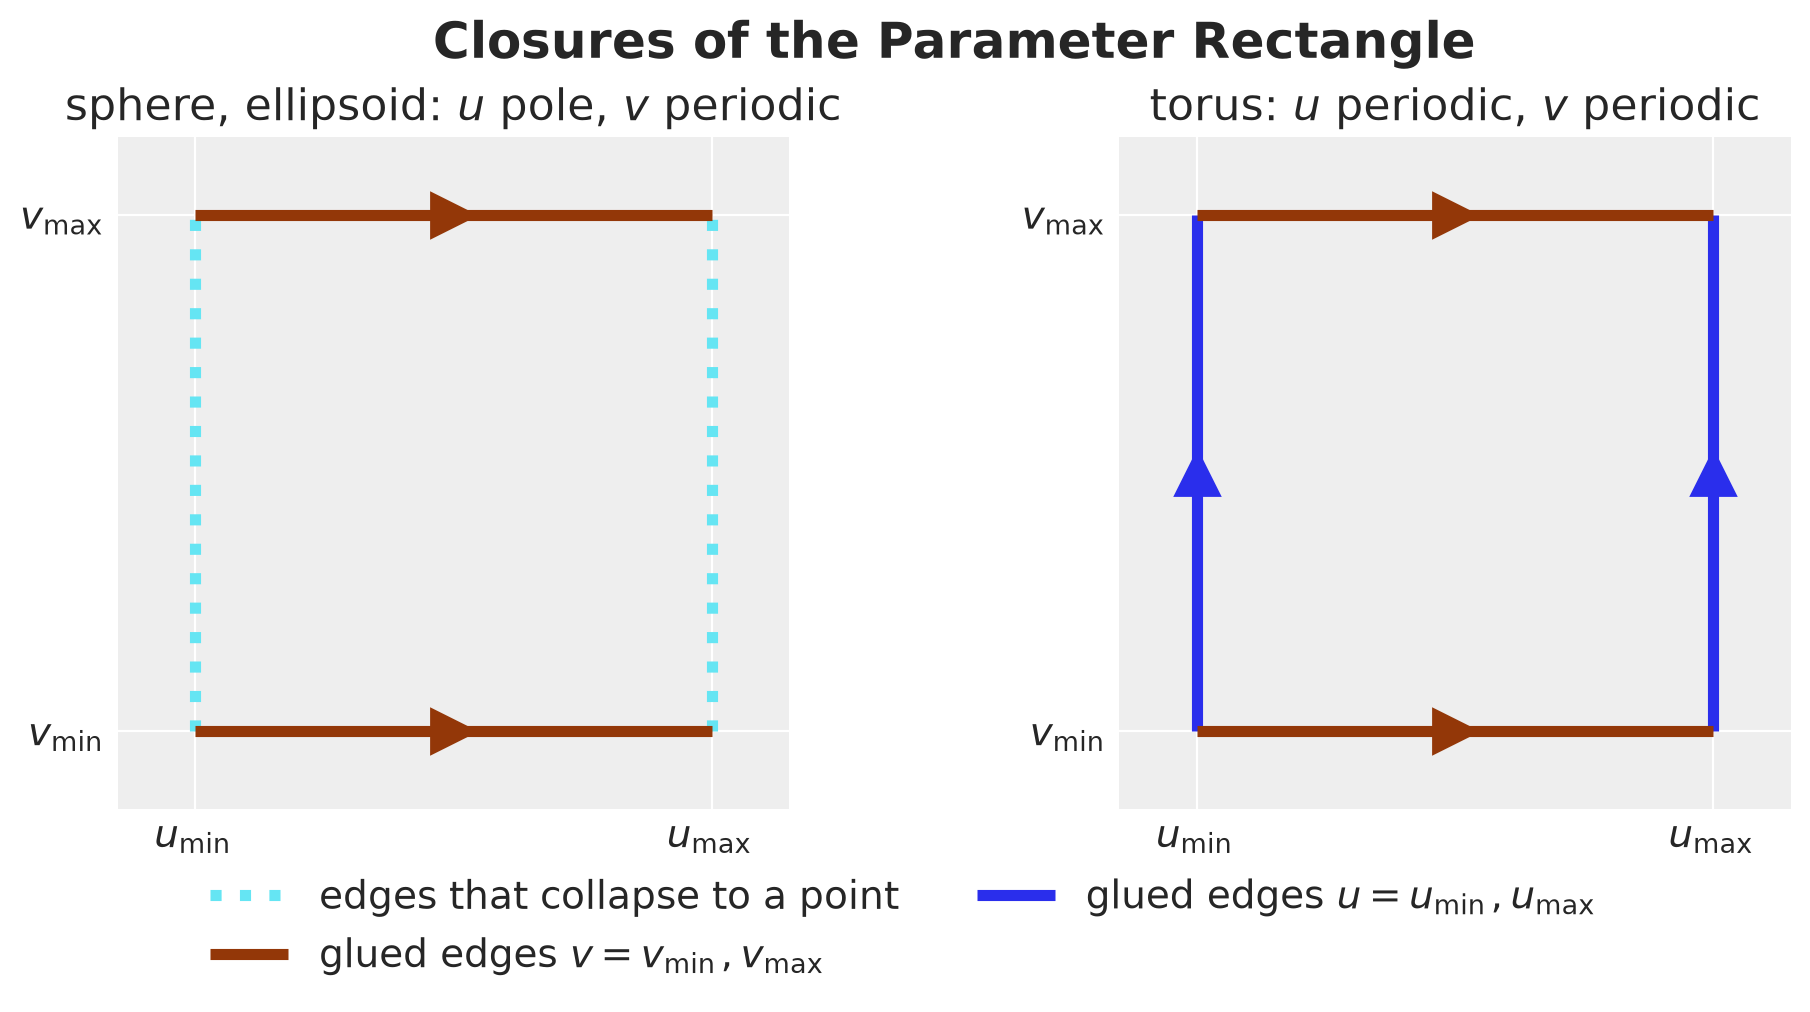

In [5]:
def edge_style(closure: Closure, glued_color: str, glued_label: str) -> dict[str, str]:
    """Line style of two opposite edges: solid if glued, dotted if collapsed."""

    if isinstance(closure, Periodic):
        return {"color": glued_color, "linestyle": "-", "label": glued_label}

    return {"color": "C5", "linestyle": ":", "label": "edges that collapse to a point"}


ARROW_STYLE = {"linestyle": "none", "markersize": 16}


def plot_closures(ax: plt.Axes, closures: tuple[Closure, Closure]) -> None:
    """Draw the parameter rectangle as a unit square, with edges styled by closure."""
    u_closure, v_closure = closures
    u_style = edge_style(u_closure, "C0", r"glued edges $u = u_{\min}, u_{\max}$")
    v_style = edge_style(v_closure, "C4", r"glued edges $v = v_{\min}, v_{\max}$")
    ax.vlines([0, 1], 0, 1, linewidth=4, **u_style)
    ax.hlines([0, 1], 0, 1, linewidth=4, **v_style)

    # Arrows in the same direction show how two glued edges line up.
    if isinstance(u_closure, Periodic):
        ax.plot([0, 1], [0.5, 0.5], marker="^", color="C0", **ARROW_STYLE)

    if isinstance(v_closure, Periodic):
        ax.plot([0.5, 0.5], [0, 1], marker=">", color="C4", **ARROW_STYLE)


CLOSURE_PANELS = {
    "sphere, ellipsoid: $u$ pole, $v$ periodic": (Pole(), Periodic()),
    "torus: $u$ periodic, $v$ periodic": (Periodic(), Periodic()),
}

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 5), layout="constrained")

for ax, (title, closures) in zip(axes, CLOSURE_PANELS.items(), strict=True):
    plot_closures(ax, closures)
    ax.set(
        title=title,
        xticks=[0, 1],
        xticklabels=[r"$u_{\min}$", r"$u_{\max}$"],
        yticks=[0, 1],
        yticklabels=[r"$v_{\min}$", r"$v_{\max}$"],
        xlim=(-0.15, 1.15),
        ylim=(-0.15, 1.15),
        aspect="equal",
    )

legend_entries = {
    label: handle
    for ax in axes
    for handle, label in zip(*ax.get_legend_handles_labels(), strict=True)
}
fig.legend(
    legend_entries.values(), legend_entries.keys(), loc="outside lower center", ncol=2
)
fig.suptitle("Closures of the Parameter Rectangle", fontsize=18, fontweight="bold");

The diagram shows how each rectangle closes up:

- **Sphere and ellipsoid.** Each dotted edge shrinks to a pole, the left one to the north pole and the right one to the south pole. The two $v$ edges meet along a meridian, the seam of the azimuth.
- **Torus.** Gluing the two $u$ edges rolls the rectangle into a tube. Gluing the two $v$ edges then bends the tube into a ring.

The base class `ClosedSurface` stores the domain and the closures of a surface, and adds the area element and the two routes to $K$:

- **`gaussian_curvature_intrinsic`:** The intrinsic route, the sectional curvature of the tangent plane as geomstats computes it (see *Derivative Chain*).
- **`gaussian_curvature_extrinsic`:** The extrinsic route, $\det h / \det g$, from the second fundamental form of geomstats (see *Derivative Chain*).

The extrinsic route does not need $N$ itself. Since $\mathrm{II}_{ij} = h_{ij} N$ and $\|N\| = 1$, the inner products of these vectors in $\mathbb{R}^3$ give

$$
\det h = h_{uu} h_{vv} - h_{uv}^2 = \langle \mathrm{II}_{uu}, \mathrm{II}_{vv} \rangle - \langle \mathrm{II}_{uv}, \mathrm{II}_{uv} \rangle.
$$

In [6]:
class ClosedSurface(ImmersedSet):
    """Closed surface in R^3 parametrized over a rectangle.

    Subclasses set the class attributes below and implement `immersion`.

    Attributes
    ----------
    domain : Domain
        Parameter rectangle, one interval per parameter.
    closures : tuple[Closure, Closure]
        How each parameter direction closes up.
    """

    domain: Domain
    closures: tuple[Closure, Closure]

    def __init__(self) -> None:
        super().__init__(dim=2)

    def _define_embedding_space(self) -> Euclidean:
        return Euclidean(dim=3)

    def area_element(
        self, points: Float[Tensor, "n_points 2"]
    ) -> Float[Tensor, " n_points"]:
        """Area element sqrt(det g)."""
        return torch.linalg.det(self.metric.metric_matrix(points)).sqrt()

    def gaussian_curvature_intrinsic(
        self, points: Float[Tensor, "n_points 2"]
    ) -> Float[Tensor, " n_points"]:
        """Intrinsic K from geomstats: the sectional curvature of the tangent plane."""
        d_u, d_v = torch.eye(2)
        return self.metric.sectional_curvature(d_u, d_v, points)

    def gaussian_curvature_extrinsic(
        self, points: Float[Tensor, "n_points 2"]
    ) -> Float[Tensor, " n_points"]:
        """Extrinsic K = det(h) / det(g), from the geomstats second fundamental form."""
        # The vectors II_ij = h_ij N, with the index of the embedding space first.
        second_form = self.metric.second_fundamental_form(points)
        ii_uu = second_form[..., 0, 0]
        ii_uv = second_form[..., 0, 1]
        ii_vv = second_form[..., 1, 1]
        inner_product = self.embedding_space.metric.inner_product
        det_h = inner_product(ii_uu, ii_vv) - inner_product(ii_uv, ii_uv)
        return det_h / torch.linalg.det(self.metric.metric_matrix(points))

### Surface Immersions

Each surface is a subclass of `ClosedSurface` that sets `domain` and `closures`, implements `immersion`, and gives the closed form of $K$, which we use only as a check.

#### Sphere

Recall the sphere of radius $\rho$ from *Induced Metric*. Its polar angle $\theta \in [0, \pi]$ ends at two poles, and its azimuth $\varphi \in [0, 2\pi]$ is periodic. Its curvature is constant, $K = 1 / \rho^2$.

The class `Sphere` implements the immersion of *Induced Metric* and this closed form:

In [7]:
class Sphere(ClosedSurface):
    """Sphere with polar angle theta in [0, pi] and azimuth phi in [0, 2 pi].

    Parameters
    ----------
    radius : float
        Radius rho of the sphere.
    """

    domain = Domain(u=Interval(0.0, torch.pi), v=Interval(0.0, 2 * torch.pi))
    closures = (Pole(), Periodic())

    def __init__(self, radius: float) -> None:
        self.radius = radius
        super().__init__()

    def immersion(self, point: Float[Tensor, "*batch 2"]) -> Float[Tensor, "*batch 3"]:
        theta, phi = point.unbind(dim=-1)
        return self.radius * torch.stack(
            [
                torch.sin(theta) * torch.cos(phi),
                torch.sin(theta) * torch.sin(phi),
                torch.cos(theta),
            ],
            dim=-1,
        )

    def gaussian_curvature_closed_form(
        self, points: Float[Tensor, "n_points 2"]
    ) -> Float[Tensor, " n_points"]:
        """Closed-form K = 1 / rho^2, used as a check."""
        return torch.full(points.shape[:-1], 1 / self.radius**2)

#### Torus

The torus with major radius $D$ (the distance from the center of the tube to the axis) and minor radius $r$ uses the angle $u$ around the tube and the angle $v$ around the hole, and both are periodic:

$$
f(u, v) = \left( (D + r \cos u) \cos v, \; (D + r \cos u) \sin v, \; r \sin u \right).
$$

Its curvature is $K = \cos u / \left( r (D + r \cos u) \right)$.

The class `Torus` implements this immersion and this closed form:

In [8]:
class Torus(ClosedSurface):
    """Ring torus with angle u around the tube and angle v around the hole.

    Parameters
    ----------
    major_radius : float
        Distance D from the center of the tube to the axis of the torus.
    minor_radius : float
        Radius r of the tube.
    """

    domain = Domain(u=Interval(0.0, 2 * torch.pi), v=Interval(0.0, 2 * torch.pi))
    closures = (Periodic(), Periodic())

    def __init__(self, major_radius: float, minor_radius: float) -> None:
        self.major_radius, self.minor_radius = major_radius, minor_radius
        super().__init__()

    def immersion(self, point: Float[Tensor, "*batch 2"]) -> Float[Tensor, "*batch 3"]:
        u, v = point.unbind(dim=-1)
        distance_to_axis = self.major_radius + self.minor_radius * torch.cos(u)
        return torch.stack(
            [
                distance_to_axis * torch.cos(v),
                distance_to_axis * torch.sin(v),
                self.minor_radius * torch.sin(u),
            ],
            dim=-1,
        )

    def gaussian_curvature_closed_form(
        self, points: Float[Tensor, "n_points 2"]
    ) -> Float[Tensor, " n_points"]:
        """Closed-form K, used as a check."""
        u, _ = points.unbind(dim=-1)
        distance_to_axis = self.major_radius + self.minor_radius * torch.cos(u)
        return torch.cos(u) / (self.minor_radius * distance_to_axis)

#### Ellipsoid

The ellipsoid stretches the sphere along its three axes. With semi-axes $a$, $b$, $c$, it uses the same coordinates as the sphere:

$$
f(\theta, \varphi) = \left( a \sin\theta \cos\varphi, \; b \sin\theta \sin\varphi, \; c \cos\theta \right).
$$

[MathWorld](https://mathworld.wolfram.com/Ellipsoid.html) gives its curvature at the point $(x, y, z) = f(\theta, \varphi)$,

$$
K = \frac{1}{a^2 b^2 c^2 \left( x^2 / a^4 + y^2 / b^4 + z^2 / c^4 \right)^2}.
$$

The sphere of radius $\rho$ is the case $a = b = c = \rho$, and the formula then gives $K = 1 / \rho^2$.

The class `Ellipsoid` implements this immersion and the closed form of MathWorld:

In [9]:
class Ellipsoid(ClosedSurface):
    """Ellipsoid with polar angle theta in [0, pi] and azimuth phi in [0, 2 pi].

    Parameters
    ----------
    a, b, c : float
        Semi-axes along x, y, and z.
    """

    domain = Domain(u=Interval(0.0, torch.pi), v=Interval(0.0, 2 * torch.pi))
    closures = (Pole(), Periodic())

    def __init__(self, a: float, b: float, c: float) -> None:
        self.a, self.b, self.c = a, b, c
        super().__init__()

    def immersion(self, point: Float[Tensor, "*batch 2"]) -> Float[Tensor, "*batch 3"]:
        theta, phi = point.unbind(dim=-1)
        return torch.stack(
            [
                self.a * torch.sin(theta) * torch.cos(phi),
                self.b * torch.sin(theta) * torch.sin(phi),
                self.c * torch.cos(theta),
            ],
            dim=-1,
        )

    def gaussian_curvature_closed_form(
        self, points: Float[Tensor, "n_points 2"]
    ) -> Float[Tensor, " n_points"]:
        """Closed-form K, used as a check."""
        x, y, z = self.immersion(points).unbind(dim=-1)
        a, b, c = self.a, self.b, self.c
        return 1 / (a * b * c * (x**2 / a**4 + y**2 / b**4 + z**2 / c**4)) ** 2

Next, let's check the curvature of the three surfaces.

## Curvature Checks

Before we integrate anything, we check $K$ pointwise, because an error in an index convention or in a nested derivative would show up here. We take the unit sphere, the torus with $D = 2$ and $r = 0.7$, and the ellipsoid with semi-axes $a = 1$, $b = 1.5$, and $c = 0.6$. For each surface we draw $20$ random points in the parameter rectangle and compute $K$ in three ways: the intrinsic route, the extrinsic route, and the closed form. We compare each route with the closed form, and the two routes with each other.

In [10]:
surfaces: dict[str, Sphere | Torus | Ellipsoid] = {
    "sphere": Sphere(radius=1.0),
    "torus": Torus(major_radius=2.0, minor_radius=0.7),
    "ellipsoid": Ellipsoid(a=1.0, b=1.5, c=0.6),
}


def random_points(
    surface: ClosedSurface, n_points: int, generator: torch.Generator
) -> Float[Tensor, "n_points 2"]:
    """Points drawn uniformly from the parameter rectangle of the surface."""
    lower = torch.tensor([interval.lower for interval in surface.domain])
    upper = torch.tensor([interval.upper for interval in surface.domain])
    return lower + (upper - lower) * torch.rand(n_points, 2, generator=generator)


class CurvatureErrors(NamedTuple):
    """Largest absolute differences between the three ways to compute K."""

    intrinsic_vs_closed_form: float
    extrinsic_vs_closed_form: float
    intrinsic_vs_extrinsic: float


def curvature_errors(
    surface: Sphere | Torus | Ellipsoid, points: Float[Tensor, "n_points 2"]
) -> CurvatureErrors:
    """Compare the intrinsic route, the extrinsic route, and the closed form."""
    # 1. The intrinsic route: the sectional curvature of geomstats.
    intrinsic = surface.gaussian_curvature_intrinsic(points)
    # 2. The extrinsic route: the second fundamental form of geomstats.
    extrinsic = surface.gaussian_curvature_extrinsic(points)
    # 3. The closed form, a formula that is known to be correct.
    closed_form = surface.gaussian_curvature_closed_form(points)
    return CurvatureErrors(
        intrinsic_vs_closed_form=(intrinsic - closed_form).abs().max().item(),
        extrinsic_vs_closed_form=(extrinsic - closed_form).abs().max().item(),
        intrinsic_vs_extrinsic=(intrinsic - extrinsic).abs().max().item(),
    )


CURVATURE_TOLERANCE = 1e-12
N_POINTS = 20

curvature_check = {
    name: curvature_errors(
        surface,
        random_points(
            surface,
            n_points=N_POINTS,
            generator=rng,
        ),
    )
    for name, surface in surfaces.items()
}

assert all(max(errors) < CURVATURE_TOLERANCE for errors in curvature_check.values())

We plot the largest absolute difference of each comparison on a log axis:

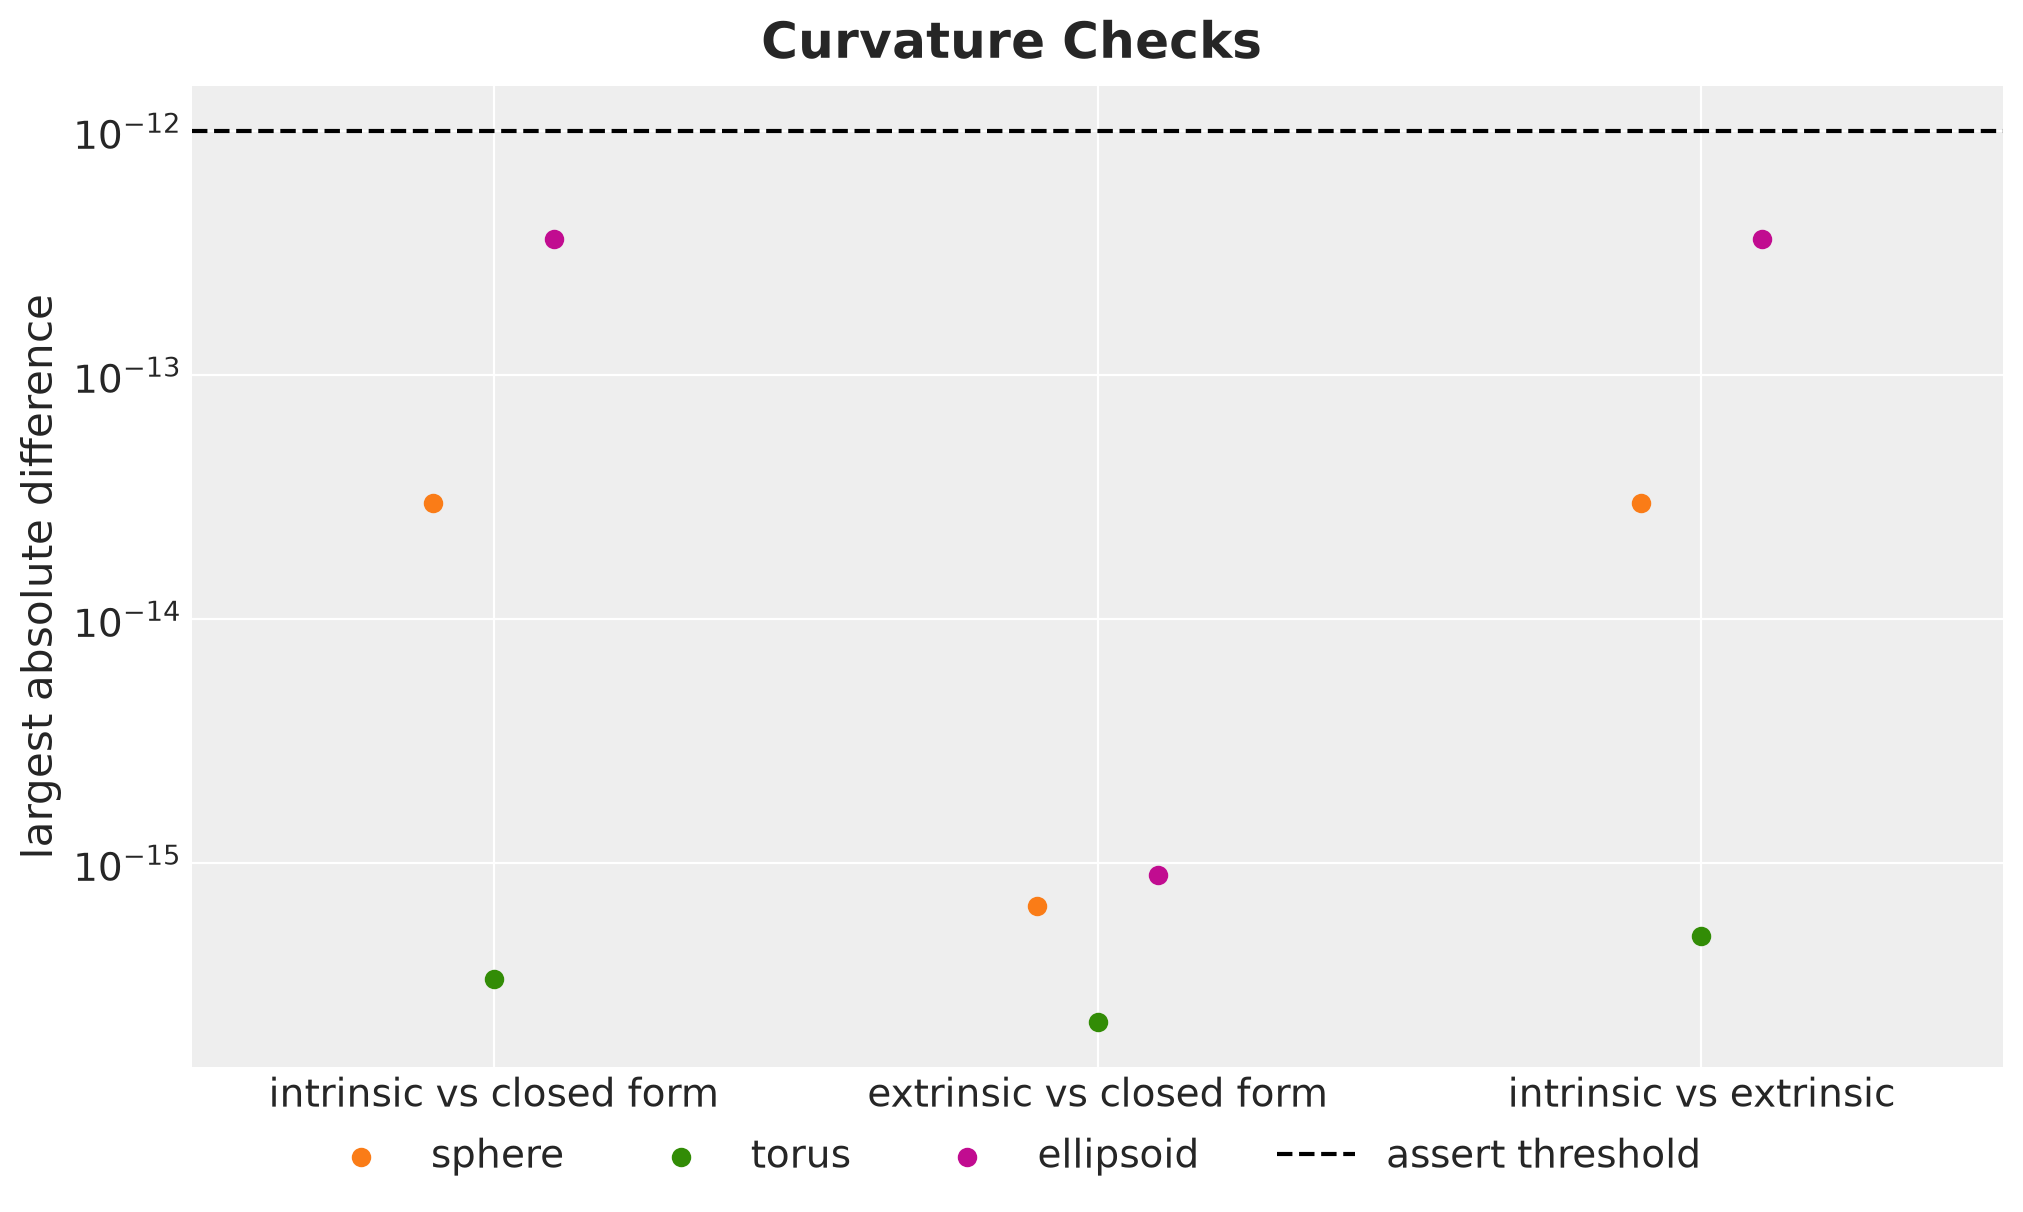

In [11]:
SURFACE_COLORS = {"sphere": "C1", "torus": "C2", "ellipsoid": "C3"}
COMPARISON_LABELS = {
    "intrinsic_vs_closed_form": "intrinsic vs closed form",
    "extrinsic_vs_closed_form": "extrinsic vs closed form",
    "intrinsic_vs_extrinsic": "intrinsic vs extrinsic",
}

fig, ax = plt.subplots()
positions = torch.arange(len(CurvatureErrors._fields))

for offset, (name, color) in zip((-0.1, 0.0, 0.1), SURFACE_COLORS.items(), strict=True):
    ax.scatter(positions + offset, curvature_check[name], color=color, label=name)

ax.axhline(CURVATURE_TOLERANCE, color="black", linestyle="--", label="assert threshold")
fig.legend(loc="outside lower center", ncol=4)
ax.set(
    yscale="log",
    xticks=positions,
    xticklabels=[COMPARISON_LABELS[field] for field in CurvatureErrors._fields],
    xlim=(-0.5, len(positions) - 0.5),
    ylabel="largest absolute difference",
)
fig.suptitle("Curvature Checks", fontsize=18, fontweight="bold");

All differences are at round-off level and below the threshold. Each comparison checks something different:

- **Intrinsic vs closed form:** It checks the whole intrinsic route of geomstats, including the nested derivative of step $3$.
- **Extrinsic vs closed form:** It checks the second fundamental form of geomstats.
- **Intrinsic vs extrinsic:** It checks the Theorema Egregium at these points: the second and the third derivatives of $f$ give the same curvature. The extrinsic route uses the Christoffel symbols of step $2$ but does not differentiate them, so this comparison adds the nested derivative of step $3$ to the steps that both routes share.

The third column looks like the first one because the extrinsic route agrees with the closed form to round-off, so the difference between the two routes is the error of the intrinsic route.

Now that we trust how geomstats computes $K$, let's look at how it varies over each surface.

## Curvature Maps

We evaluate the intrinsic $K$ at the centers of a uniform $24 \times 24$ grid on the parameter rectangle of each surface. This takes a while, because each point needs its own Riemann tensor.

In [12]:
%%time

N_CELLS = 24


def tensor_grid(
    u: Float[Tensor, " n_u"], v: Float[Tensor, " n_v"]
) -> Float[Tensor, "n_u n_v 2"]:
    """All pairs (u_p, v_q) of the two coordinates, on a grid indexed by (p, q)."""
    return torch.stack(torch.meshgrid(u, v, indexing="ij"), dim=-1)


class CurvatureMap(NamedTuple):
    """Surface points on a grid of the parameter rectangle and K at the cell centers."""

    surface_points: Float[Tensor, "n_vertices n_vertices 3"]
    curvature: Float[Tensor, "n_cells n_cells"]


def curvature_map(surface: ClosedSurface, n_cells: int = N_CELLS) -> CurvatureMap:
    """Evaluate the surface on a uniform grid and K at the cell centers."""
    u_vertices, v_vertices = (
        torch.linspace(interval.lower, interval.upper, n_cells + 1)
        for interval in surface.domain
    )
    vertices = tensor_grid(u_vertices, v_vertices)
    centers = (vertices[:-1, :-1] + vertices[1:, 1:]) / 2
    # The metric methods of geomstats expect a flat batch of points.
    curvature = surface.gaussian_curvature_intrinsic(centers.reshape(-1, 2))
    return CurvatureMap(
        surface_points=surface.immersion(vertices),
        curvature=curvature.reshape(n_cells, n_cells),
    )


curvature_maps = {name: curvature_map(surface) for name, surface in surfaces.items()}

CPU times: user 22 s, sys: 63.2 ms, total: 22 s
Wall time: 22.1 s


We color each cell of a surface by its value of $K$. The colormap is centered at $K = 0$, so red cells have positive and blue cells negative curvature.

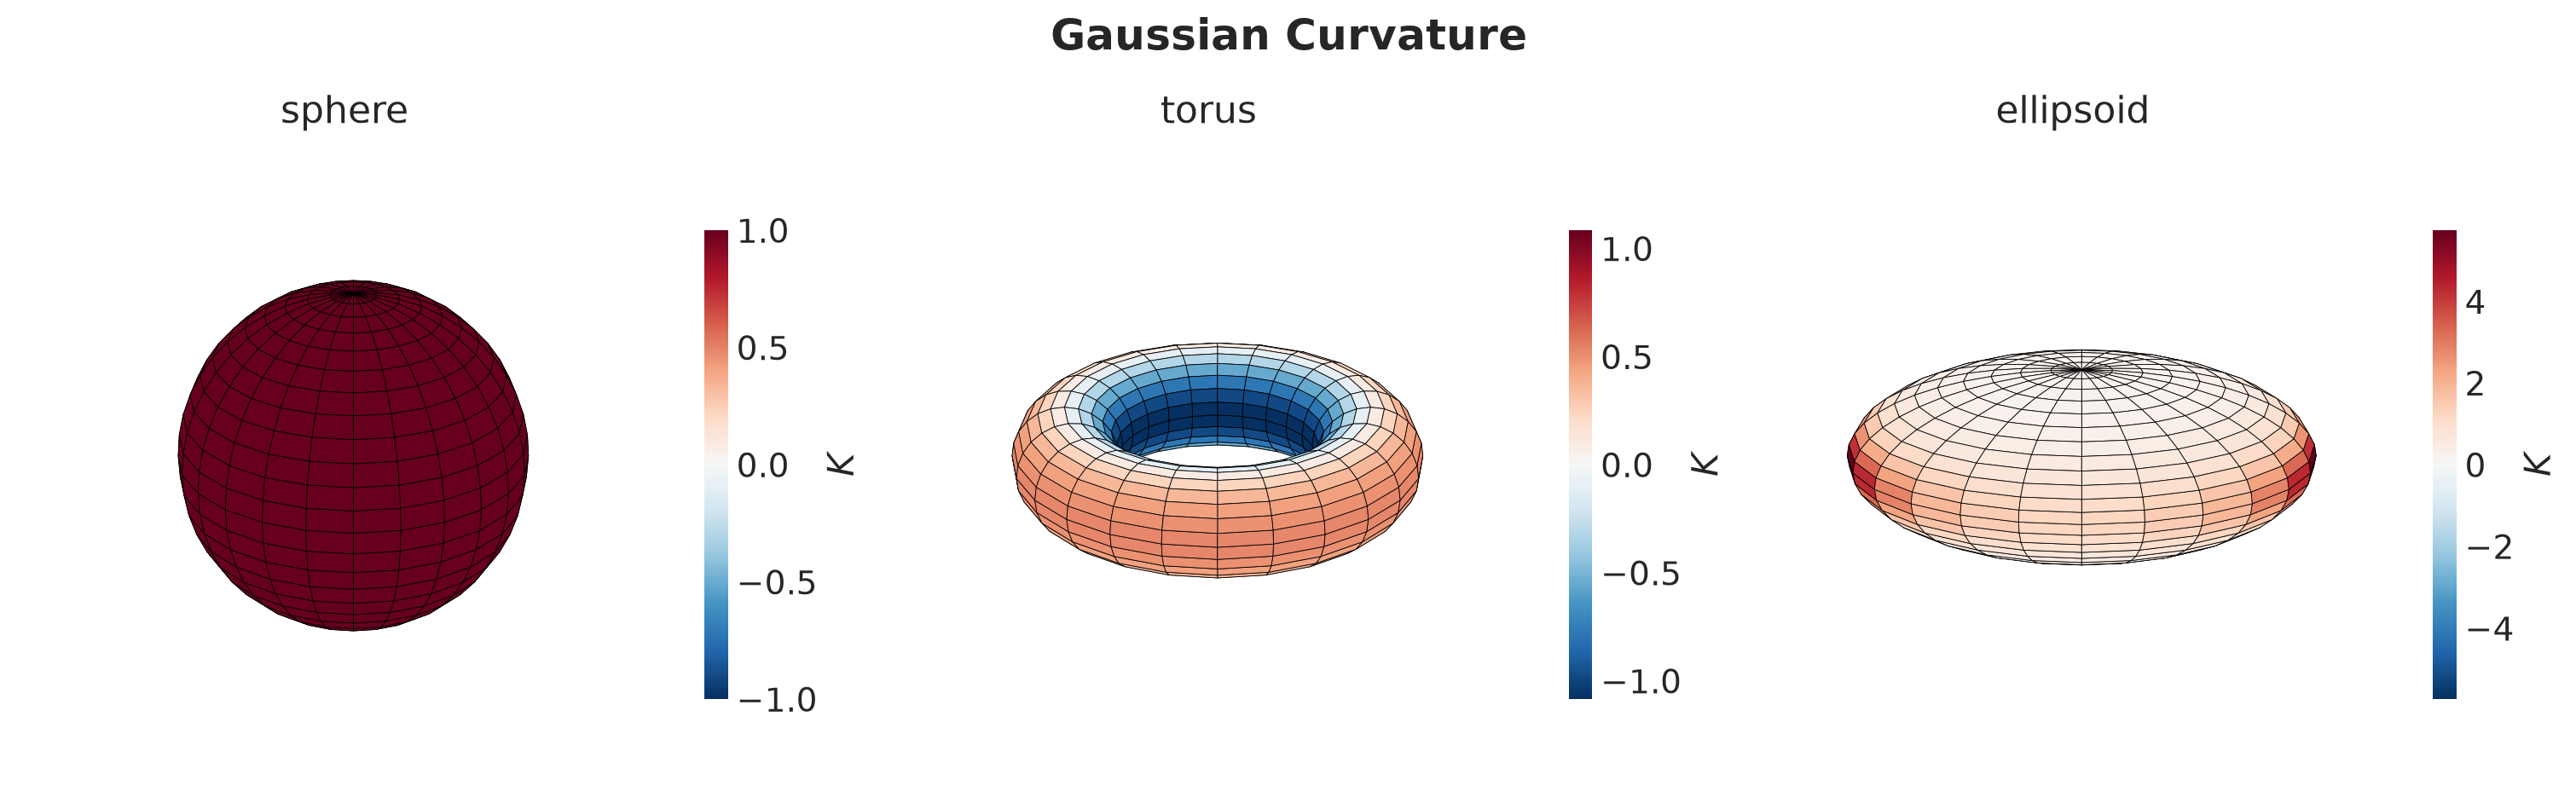

In [13]:
cmap = plt.colormaps["RdBu_r"]

fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(15, 5),
    subplot_kw={"projection": "3d"},
    layout="constrained",
)

for ax, (name, curvature_map_) in zip(axes, curvature_maps.items(), strict=True):
    norm = CenteredNorm()
    ax.plot_surface(
        *curvature_map_.surface_points.unbind(dim=-1),
        facecolors=cmap(norm(curvature_map_.curvature)),
        edgecolor="black",
        linewidth=0.3,
        shade=False,
    )
    ax.set_aspect("equal")
    ax.view_init(elev=25, azim=0)
    ax.set_axis_off()
    ax.set_facecolor("white")
    ax.set_title(name)
    fig.colorbar(
        plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, shrink=0.6, label="$K$"
    )

fig.suptitle("Gaussian Curvature", fontsize=18, fontweight="bold");

The colors show where each surface curves:

- **Sphere.** It has a single color because its curvature is constant.
- **Torus.** It is red on the outer half and blue on the inner half, the two parts that cancel in its total curvature. From the closed form, the inner half is more curved, down to $-1 / \left( r (D - r) \right) \approx -1.10$ against up to $1 / \left( r (D + r) \right) \approx 0.53$, but it has less area.
- **Ellipsoid.** It is red near the two ends of its longest axis and almost white elsewhere, so its curvature is concentrated near these ends. The closed form gives $K = b^2 / (a^2 c^2) = 6.25$ there, and the colorbar stops below that value because the cell centers miss the ends.

Next, let's integrate $K$ over each surface.

## Total Curvature

We now turn to the left side of the theorem. Over the parameter rectangle, the total curvature is

$$
\int_M K \, dA = \int_{u_{\min}}^{u_{\max}} \int_{v_{\min}}^{v_{\max}} K(u, v) \sqrt{\det g(u, v)} \, dv \, du.
$$

For the examples we have at hand, we can compute this integral in closed form. Nevertheless, we will approximate it by a weighted sum of values of the integrand, as we are exploring how to use Python to "avoid" any analytical calculation (this does not mean we should not do it!). Let's see how this works in one dimension first.

### Quadrature Rules

A **quadrature rule** on an interval $[t_{\min}, t_{\max}]$ consists of $n$ **nodes** $t_1, \ldots, t_n$, where we evaluate the integrand $\psi$, and $n$ **weights** $\omega_1, \ldots, \omega_n$, which say how much each value counts:

$$
\int_{t_{\min}}^{t_{\max}} \psi(t) \, dt \approx \sum_{p=1}^{n} \omega_p \, \psi(t_p).
$$

Think of the weight $\omega_p$ as the length of the piece of the interval that the node $t_p$ stands for. The weights add up to $t_{\max} - t_{\min}$, so a rule integrates a constant exactly.

We use two rules, and the closure of a direction decides which one (see *Base Class*):

- **Midpoint rule, for a periodic direction:** It splits the interval into $n$ cells of width $\delta = (t_{\max} - t_{\min}) / n$, puts a node at the center of each cell, and gives every node the weight $\delta$. For a periodic integrand, its error shrinks geometrically, by a constant factor per added node.
- **[Gauss-Legendre rule](https://en.wikipedia.org/wiki/Gauss%E2%80%93Legendre_quadrature), for a direction that ends at poles:** Its nodes are the roots of the Legendre polynomial of degree $n$, mapped to the interval, and they cluster near the two ends. Toward the poles, the error of the midpoint rule would shrink only like $1 / n^2$, while the error of the Gauss-Legendre rule still shrinks geometrically.

The *Appendix* shows the nodes and the weights of both rules and explains their errors.

Both rules only use interior nodes. This matters because $\det g = 0$ at a pole, so the inverse metric $g^{-1}$ in the Christoffel symbols does not exist there.

The functions below return the nodes and the weights of a rule on an interval, and `QUADRATURE_RULES` maps each type of closure to its rule:

In [14]:
class QuadratureRule(NamedTuple):
    """Nodes and weights of a one-dimensional quadrature rule."""

    nodes: Float[Tensor, " n_nodes"]
    weights: Float[Tensor, " n_nodes"]


def midpoint_rule(lower: float, upper: float, n_nodes: int) -> QuadratureRule:
    """Composite midpoint rule on [lower, upper], for a periodic direction."""
    step = (upper - lower) / n_nodes
    nodes = lower + step * (torch.arange(n_nodes) + 0.5)
    return QuadratureRule(nodes=nodes, weights=torch.full_like(nodes, step))


def gauss_legendre_rule(lower: float, upper: float, n_nodes: int) -> QuadratureRule:
    """Gauss-Legendre rule on [lower, upper], for a direction that ends at poles."""
    nodes, weights = (torch.from_numpy(array) for array in leggauss(n_nodes))
    half_width = (upper - lower) / 2
    return QuadratureRule(
        nodes=lower + half_width * (nodes + 1), weights=half_width * weights
    )


QUADRATURE_RULES: dict[type[Closure], Callable[[float, float, int], QuadratureRule]] = {
    Periodic: midpoint_rule,
    Pole: gauss_legendre_rule,
}

Now that each direction has its rule, we combine the two rules on the rectangle.

### Tensor Product

On the rectangle we use one rule in each direction, the one that its closure picks. The first direction has nodes $u_p$ with weights $\alpha_p$, and the second direction has nodes $v_q$ with weights $\beta_q$, for $p, q = 1, \ldots, n$.

To integrate a function $\Psi(u, v)$ over the rectangle, we apply the rule for $v$ at each fixed $u = u_p$, and then the rule for $u$ to the results:

$$
\int_{u_{\min}}^{u_{\max}} \int_{v_{\min}}^{v_{\max}} \Psi(u, v) \, dv \, du \approx \sum_{p=1}^{n} \alpha_p \left( \sum_{q=1}^{n} \beta_q \, \Psi(u_p, v_q) \right) = \sum_{p=1}^{n} \sum_{q=1}^{n} \alpha_p \beta_q \, \Psi(u_p, v_q).
$$

So the grid point $(u_p, v_q)$ gets the weight $\alpha_p \beta_q$, the area of the small rectangle with sides $\alpha_p$ and $\beta_q$ that it stands for. With $\Psi = K \sqrt{\det g}$, the total curvature is

$$
\int_M K \, dA \approx \sum_{p=1}^{n} \sum_{q=1}^{n} \alpha_p \beta_q \, K(u_p, v_q) \sqrt{\det g(u_p, v_q)}.
$$

In code, `tensor_product_rule` pairs the nodes of the two rules with `tensor_grid` from *Curvature Maps* and multiplies their weights. Then `gb_curvature`, the left side of the Gauss-Bonnet theorem, sums $K \sqrt{\det g}$ times the weights:

In [15]:
class TensorProductRule(NamedTuple):
    """Points and weights of a quadrature rule on the parameter rectangle."""

    points: Float[Tensor, "n_points 2"]
    weights: Float[Tensor, " n_points"]


def tensor_product_rule(surface: ClosedSurface, n_nodes: int) -> TensorProductRule:
    """Tensor product of the rules that the closures pick in each direction."""
    u_rule, v_rule = (
        QUADRATURE_RULES[type(closure)](interval.lower, interval.upper, n_nodes)
        for interval, closure in zip(surface.domain, surface.closures, strict=True)
    )
    return TensorProductRule(
        points=tensor_grid(u_rule.nodes, v_rule.nodes).reshape(-1, 2),
        weights=torch.outer(u_rule.weights, v_rule.weights).reshape(-1),
    )


def gb_curvature(surface: ClosedSurface, n_nodes: int) -> float:
    """Left side of Gauss-Bonnet: the integral of K dA by tensor-product quadrature."""
    rule = tensor_product_rule(surface, n_nodes)
    curvature = surface.gaussian_curvature_intrinsic(rule.points)
    integrand = curvature * surface.area_element(rule.points)
    return (rule.weights * integrand).sum().item()

For the torus, $\sqrt{\det g} = r (D + r \cos u)$, so the integrand is $K \sqrt{\det g} = \cos u$. The midpoint rule integrates $\cos u$ over a full period exactly for $n \geq 2$.

As a first test, we integrate over the torus with only $n = 2$ nodes per direction, where we expect an exact result:

In [16]:
GB_TOLERANCE = 1e-5

torch.testing.assert_close(
    gb_curvature(surfaces["torus"], n_nodes=2),
    0.0,
    atol=GB_TOLERANCE,
    rtol=0.0,
)

The result is zero up to round-off, as we expected.

With the left side in place, we turn to the right side.

## Euler Characteristic

For the right side we need $\chi = V - E + F$. We build a polygonal decomposition from a grid of $n_{\text{cells}} \times n_{\text{cells}}$ quads on the parameter rectangle and glue it according to the closures. Each grid vertex gets an integer label, and glued vertices share a label.

Recall from *Base Class* that each closure glues the first and the last row of a grid with its method `glue`. So `glued_labels` moves each direction to the front, glues it, and moves it back.

Let's work a small example. Here are the labels of the sphere grid with $n_{\text{cells}} = 4$, where rows follow the polar angle $\theta$ and columns follow the azimuth $\varphi$:

In [17]:
def glued_labels(
    closures: tuple[Closure, Closure], n_cells: int
) -> Int[Tensor, "n_vertices n_vertices"]:
    """Labels of the grid vertices, of shape [n_cells + 1, n_cells + 1].

    Glued vertices share a label.
    """
    labels = torch.arange((n_cells + 1) ** 2).reshape(n_cells + 1, n_cells + 1)

    for dim, closure in enumerate(closures):
        labels = closure.glue(labels.movedim(dim, 0)).movedim(0, dim)

    return labels


glued_labels(surfaces["sphere"].closures, n_cells=4)

tensor([[ 0,  0,  0,  0,  0],
        [ 5,  6,  7,  8,  5],
        [10, 11, 12, 13, 10],
        [15, 16, 17, 18, 15],
        [20, 20, 20, 20, 20]])

The labels are the vertex numbers of the grid before gluing. The first row carries the single label $0$ and the last row the single label $20$: these are the two poles. The last column repeats the first column, which glues the seam of the azimuth.

We then count the cells of the glued grid:

- **Vertices:** We count the distinct labels.
- **Edges:** We list the two end labels of every edge between neighboring grid vertices. We drop an edge on a pole, whose two end labels are equal, and we keep one of two edges that are glued along a seam, which have the same end labels.
- **Faces:** A quad that touches a pole loses one corner and becomes a triangle, so every quad stays a face and $F = n_{\text{cells}}^2$.

Identifying an edge by its two end labels needs at least three cells per direction: with two cells, two different edges of a periodic direction join the same two vertices.

In [18]:
def grid_edges(labels: Int[Tensor, "n_rows n_cols"]) -> Int[Tensor, "n_edges 2"]:
    """End labels of the edges between neighboring vertices of the grid."""
    along_rows = torch.stack([labels[:-1], labels[1:]], dim=-1)
    along_cols = torch.stack([labels[:, :-1], labels[:, 1:]], dim=-1)
    return torch.cat([along_rows.reshape(-1, 2), along_cols.reshape(-1, 2)])


def distinct_edges(labels: Int[Tensor, "n_rows n_cols"]) -> Int[Tensor, "n_distinct 2"]:
    """Edges of the glued grid, each counted once."""
    edges = grid_edges(labels)
    # An edge on a pole collapses to a point.
    edges = edges[edges[:, 0] != edges[:, 1]]
    # Glued edges have the same two end labels.
    return edges.sort(dim=-1).values.unique(dim=0)


class CellCount(NamedTuple):
    """Numbers of vertices, edges, and faces of a glued grid."""

    vertices: int
    edges: int
    faces: int

    @property
    def euler_characteristic(self) -> int:
        return self.vertices - self.edges + self.faces


def count_cells(closures: tuple[Closure, Closure], n_cells: int) -> CellCount:
    """Count the vertices, edges, and faces of the glued grid.

    Needs n_cells >= 3, so that no two edges join the same two vertices.
    """
    labels = glued_labels(closures, n_cells)
    return CellCount(
        vertices=labels.unique().numel(),
        edges=len(distinct_edges(labels)),
        faces=n_cells**2,
    )


count_cells(surfaces["sphere"].closures, n_cells=4)

CellCount(vertices=14, edges=28, faces=16)

For the sphere grid we get $\chi = 14 - 28 + 16 = 2$. We now write $\chi$ as a function `euler_characteristic` of the surface, and check with an `assert` that its value does not depend on the grid size:

In [19]:
def euler_characteristic(surface: ClosedSurface, n_cells: int = 12) -> int:
    """Euler characteristic V - E + F of the glued grid on the surface."""
    return count_cells(surface.closures, n_cells).euler_characteristic


N_CELLS = (4, 8, 16)

assert all(
    euler_characteristic(surface, n_cells) == euler_characteristic(surface)
    for surface in surfaces.values()
    for n_cells in N_CELLS
)

{name: euler_characteristic(surface) for name, surface in surfaces.items()}

{'sphere': 2, 'torus': 0, 'ellipsoid': 2}

The sphere and the ellipsoid have $\chi = 2$ and the torus has $\chi = 0$, which matches $\chi = 2 - 2 \, \text{genus}$ with genus $0$ and $1$.

Now that we have both sides, we can compare them.

## Gauss-Bonnet Check

Finally, we put both sides together as functions of a surface:

- **Left side:** `gb_curvature` computes the integral of $K \, dA$ with $n$ quadrature nodes per direction.
- **Right side:** `gb_euler_characteristic` computes $2 \pi \chi$ from `euler_characteristic`.

First, let's see how fast the left side converges. We compute the absolute difference between both sides for $n = 4, 8, 16, 32$ nodes per direction:

In [20]:
def gb_euler_characteristic(surface: ClosedSurface) -> float:
    """Right side of Gauss-Bonnet: 2 pi chi."""
    return 2 * torch.pi * euler_characteristic(surface)


N_NODES = (4, 8, 16, 32)

gauss_bonnet_errors = {
    name: [
        abs(gb_curvature(surface, n_nodes) - gb_euler_characteristic(surface))
        for n_nodes in N_NODES
    ]
    for name, surface in surfaces.items()
}

We plot these differences against $n$ on a log axis, together with the tolerance $10^{-5}$ of the check below:

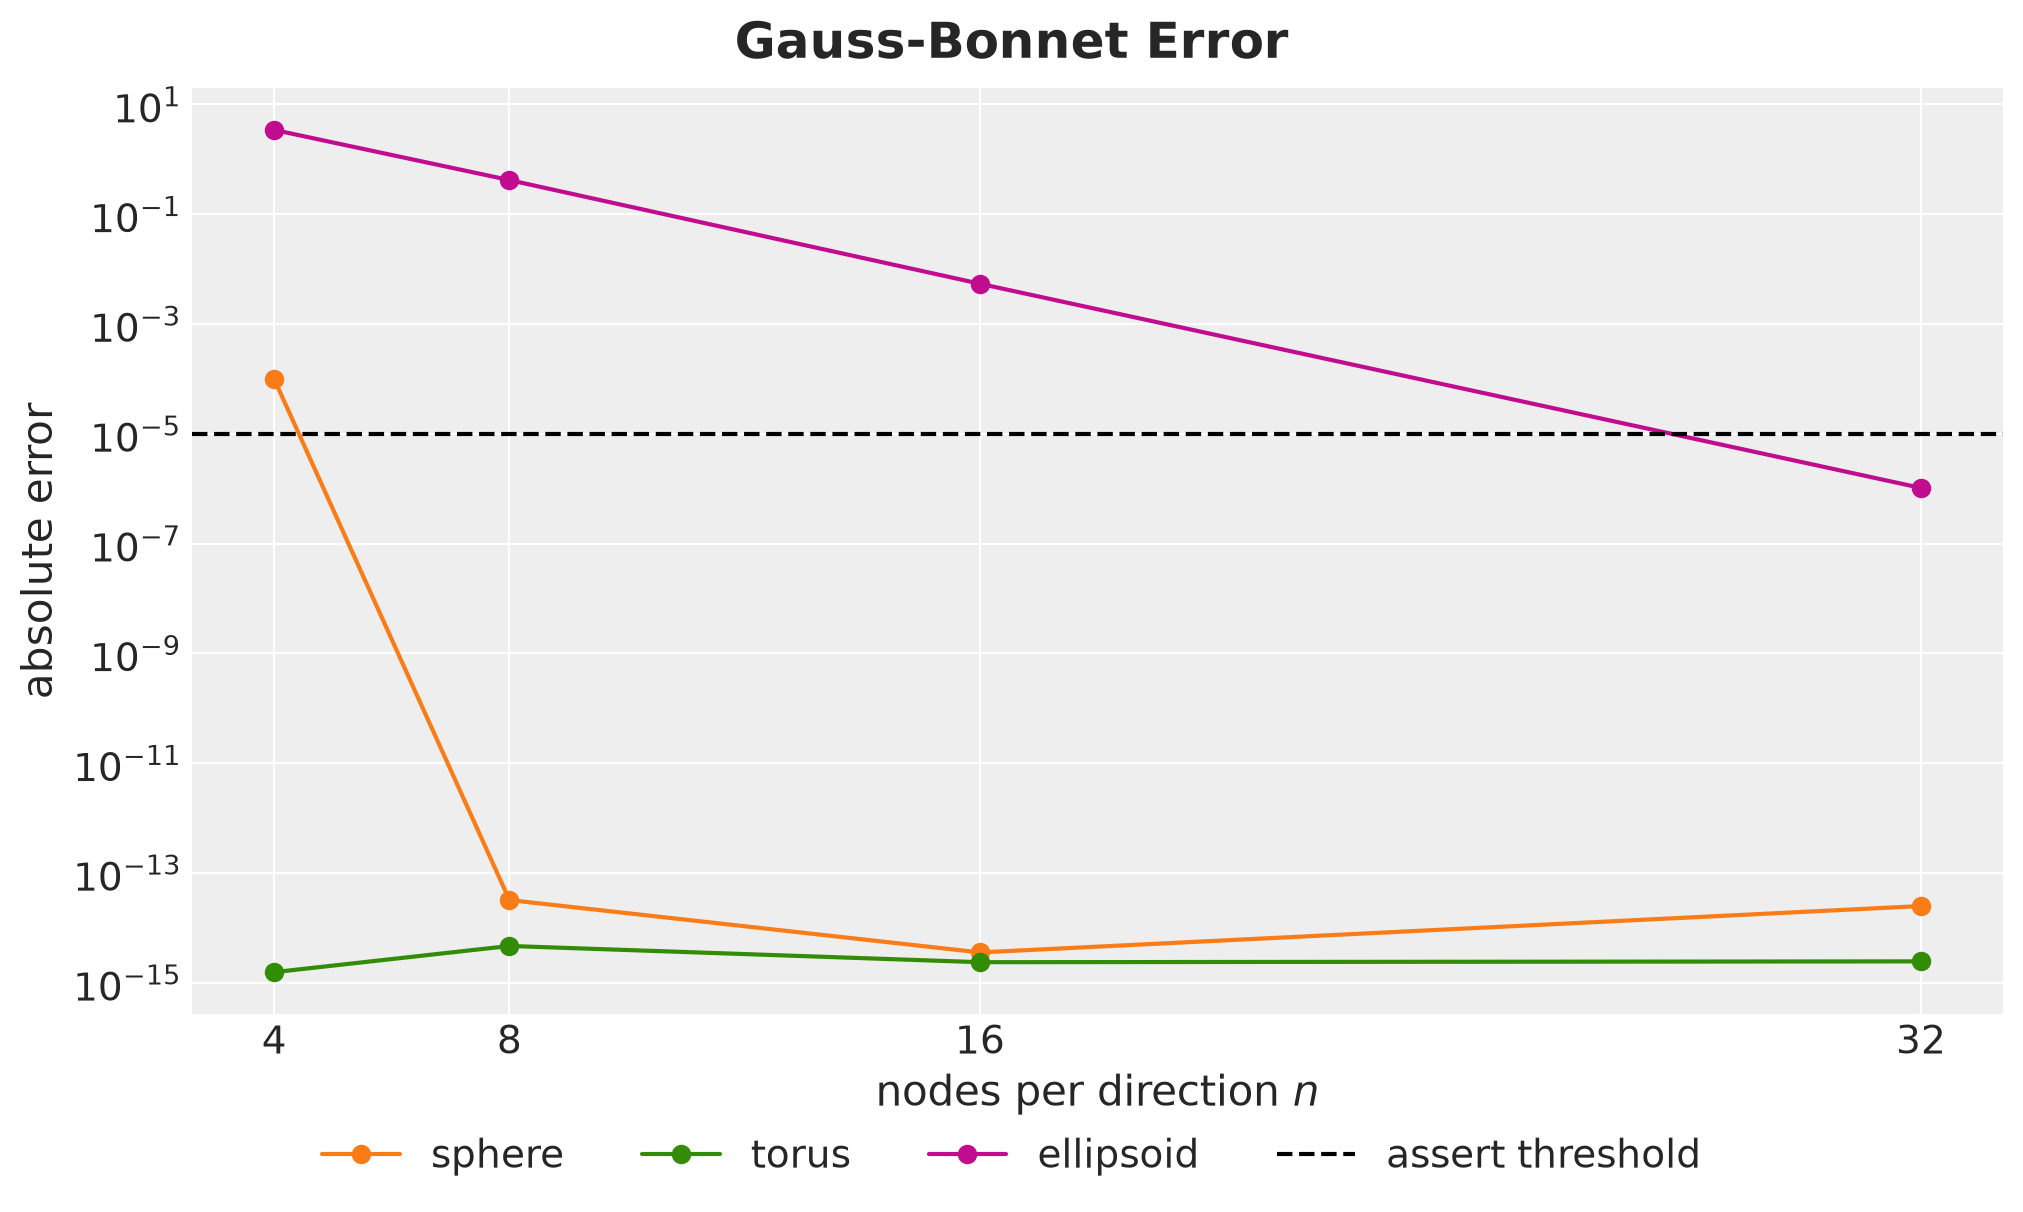

In [21]:
fig, ax = plt.subplots(layout="constrained")

for name, color in SURFACE_COLORS.items():
    ax.plot(N_NODES, gauss_bonnet_errors[name], marker="o", color=color, label=name)

ax.axhline(GB_TOLERANCE, color="black", linestyle="--", label="assert threshold")
ax.set(
    yscale="log",
    xticks=N_NODES,
    xlabel="nodes per direction $n$",
    ylabel="absolute error",
)
fig.legend(loc="outside lower center", ncol=4)
fig.suptitle("Gauss-Bonnet Error", fontsize=18, fontweight="bold");

The three surfaces converge at different rates:

- **Sphere.** The error drops to round-off with $n = 8$ nodes per direction.
- **Torus.** The error stays at round-off for every $n$, as the midpoint rule predicts.
- **Ellipsoid.** The error falls by a constant factor per added node, a straight line on the log axis, which is geometric convergence. It needs more nodes than the sphere, which is consistent with its curvature being concentrated near the ends of its longest axis.

The ellipsoid crosses the threshold between $n = 16$ and $n = 32$, so we check the theorem with $n = 32$ nodes per direction.

The left side is a quadrature, so it differs from $2 \pi \chi$ by a truncation error that shrinks with $n$. We check that both sides agree up to the absolute tolerance $10^{-5}$, with `rtol=0.0`. The tolerance is absolute because the truncation error does not grow with the size of $2 \pi \chi$, and because the right side is $0$ for the torus.

With $n = 32$, the check needs $3072$ points in total ($3$ surfaces times $32^2 = 1024$ points), each with its own Riemann tensor:

In [22]:
%%time

for surface in surfaces.values():
    torch.testing.assert_close(
        gb_curvature(surface, n_nodes=32),
        gb_euler_characteristic(surface),
        atol=GB_TOLERANCE,
        rtol=0.0,
    )

CPU times: user 41.3 s, sys: 138 ms, total: 41.4 s
Wall time: 41.6 s


The two sides of the theorem agree for all three surfaces! The cell took about $41$ seconds for the $3072$ points, or about $13$ milliseconds per point.

The details of the quadrature rules follow in the *Appendix*.

## Appendix

This appendix gives the details of the quadrature rules of *Total Curvature*.

### Nodes and Weights

Let's compare the two rules on $[0, \pi]$, the range of the polar angle, with $n = 8$ nodes. Each stem marks a node, and its height is the weight of the node:

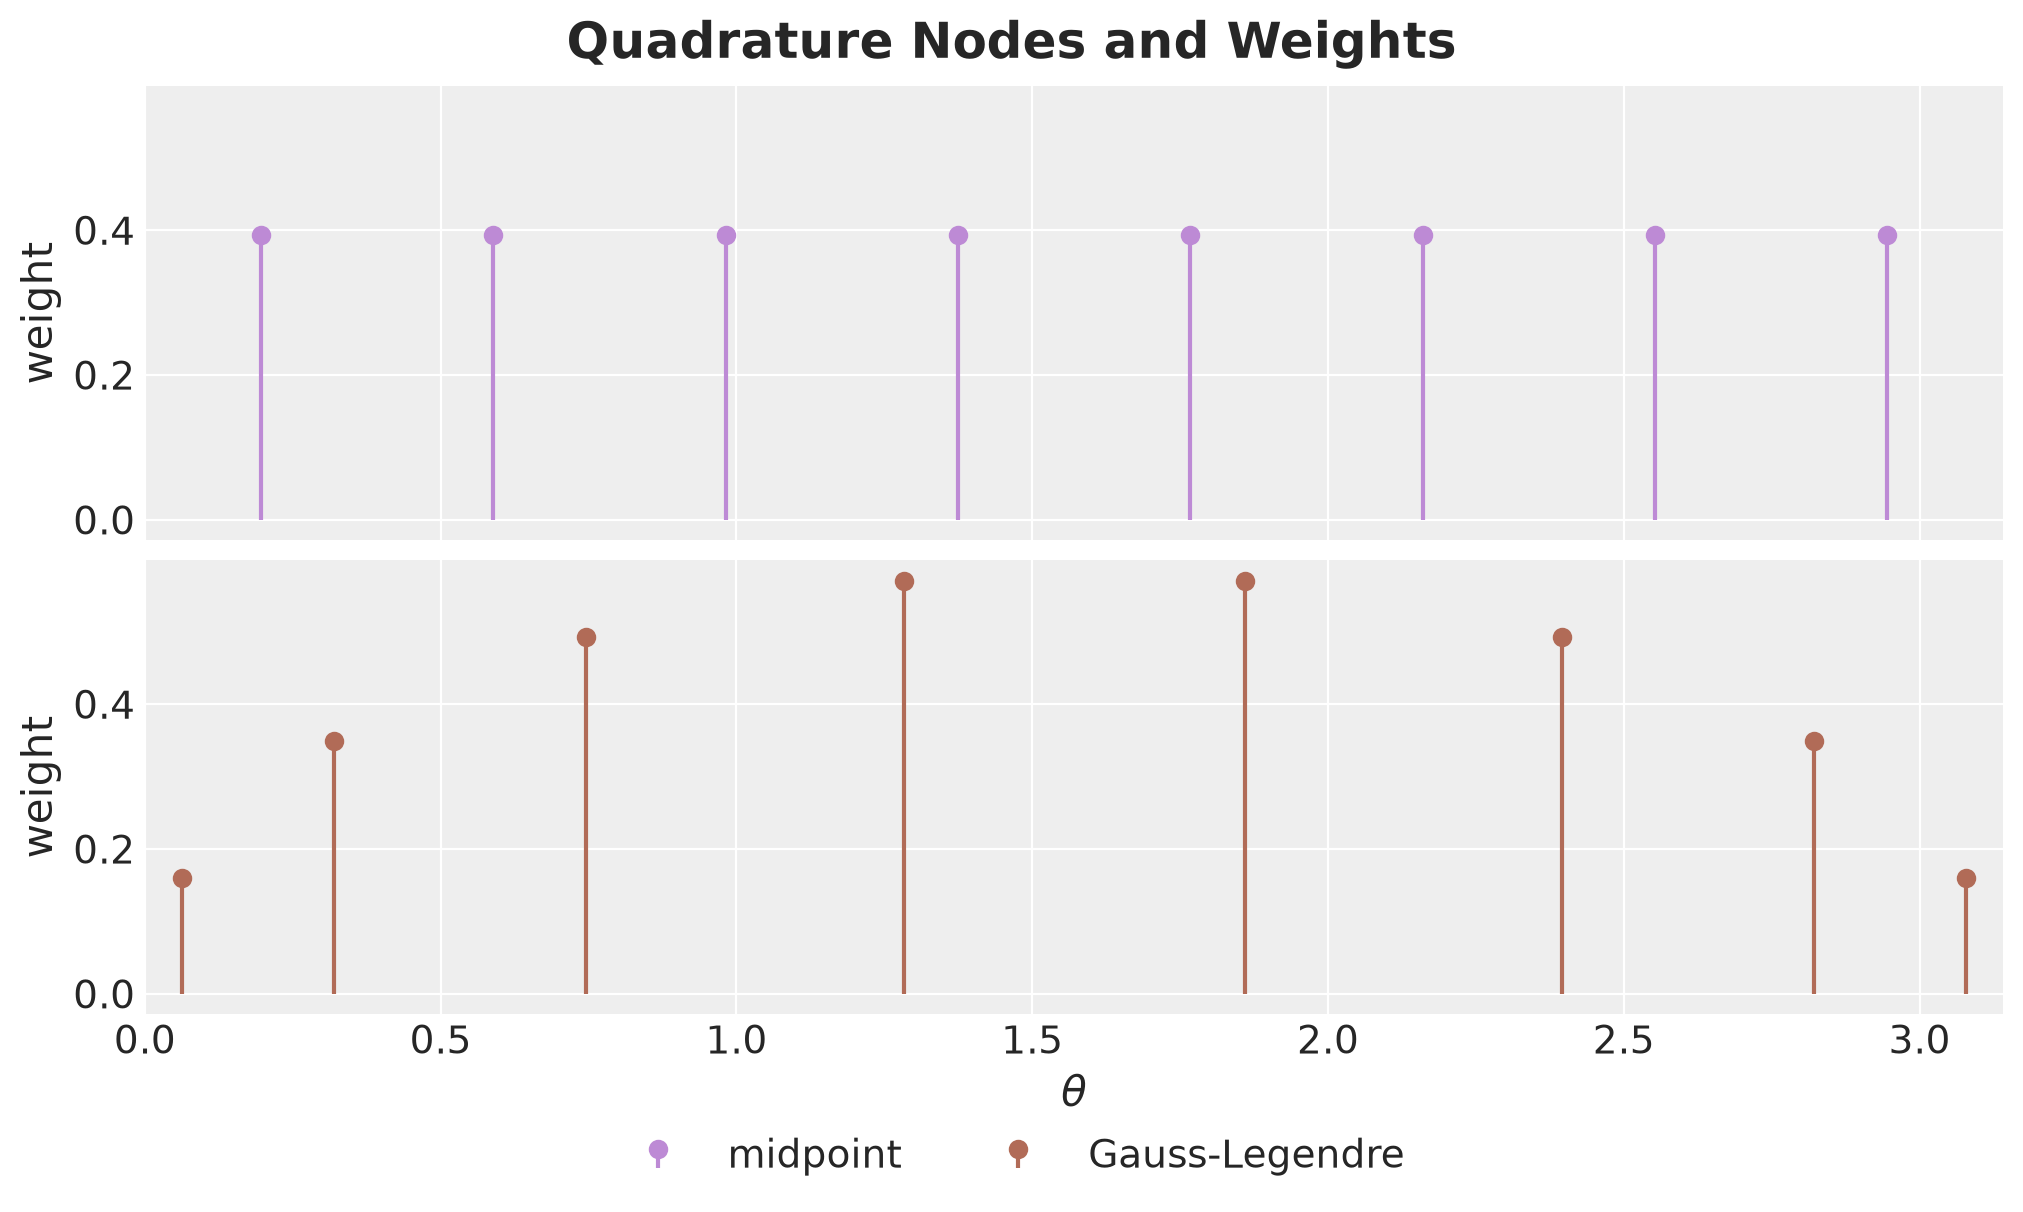

In [23]:
RULES = {"midpoint": midpoint_rule, "Gauss-Legendre": gauss_legendre_rule}
RULE_COLORS = {"midpoint": "C8", "Gauss-Legendre": "C9"}

fig, axes = plt.subplots(
    nrows=2, ncols=1, sharex=True, sharey=True, layout="constrained"
)

for ax, (name, rule) in zip(axes, RULES.items(), strict=True):
    nodes, weights = rule(0.0, torch.pi, 8)
    assert torch.isclose(weights.sum(), torch.tensor(torch.pi))
    color = RULE_COLORS[name]
    ax.stem(
        nodes, weights, linefmt=color, markerfmt=f"{color}o", basefmt=" ", label=name
    )
    ax.set(ylabel="weight")

axes[-1].set(xlabel=r"$\theta$", xlim=(0, torch.pi))
fig.legend(loc="outside lower center", ncol=2)
fig.suptitle("Quadrature Nodes and Weights", fontsize=18, fontweight="bold");

The figure shows how the two rules spend their weight, which adds up to $\pi$ in both:

- **Midpoint rule.** It treats every part of the interval alike.
- **Gauss-Legendre rule.** It puts more nodes near the two ends, but gives each of them a small weight.

### Error of the Rules

To see why each closure gets its rule, we look at the **error** of a rule, the exact integral minus the weighted sum, and at how fast it shrinks when we add nodes.

Let's start with the midpoint rule on the cell of width $\delta$ around the node $t_p$. A Taylor expansion of $\psi$ around $t_p$ gives

$$
\int_{t_p - \delta / 2}^{t_p + \delta / 2} \psi(t) \, dt = \delta \, \psi(t_p) + \frac{\delta^3}{24} \psi''(t_p) + \ldots,
$$

because the odd powers of $t - t_p$ integrate to zero over the cell, which is symmetric around $t_p$. The first term is what the midpoint rule computes, so this cell leaves an error of about $\delta^3 \psi''(t_p) / 24$.

We add the errors of all cells and pull out $\delta^2$. The remaining sum is the midpoint rule applied to $\psi''$, so it is close to the integral of $\psi''$:

$$
\sum_{p=1}^{n} \frac{\delta^3}{24} \psi''(t_p) = \frac{\delta^2}{24} \sum_{p=1}^{n} \delta \, \psi''(t_p) \approx \frac{\delta^2}{24} \int_{t_{\min}}^{t_{\max}} \psi''(t) \, dt = \frac{\delta^2}{24} \left( \psi'(t_{\max}) - \psi'(t_{\min}) \right).
$$

In other words, the leading error of the midpoint rule depends only on the slopes of the integrand at the two ends of the interval. This explains the two cases:

- **Periodic direction:** The two ends are the same point of the surface, so the slopes agree and the leading error vanishes.
- **Direction that ends at poles:** The two ends are different points, the north and the south pole, and the slopes differ. So the leading error stays, and with $\delta = \pi / n$ it shrinks only like $1 / n^2$: doubling the number of nodes divides the error by four.

In the periodic case, the smaller error terms vanish as well. The [Euler-Maclaurin formula](https://en.wikipedia.org/wiki/Euler%E2%80%93Maclaurin_formula) gives the next term as $\delta^4$ times a constant times $\psi'''(t_{\max}) - \psi'''(t_{\min})$, then the same with $\delta^6$ and the fifth derivative, and so on. Every term is a difference of one derivative between the two ends, so every term vanishes.

So in a periodic direction the error of the midpoint rule shrinks faster than any power of $1 / n$. Our integrands are analytic, that is, a convergent power series describes them around every point. For such a periodic integrand, the error shrinks geometrically, by a constant factor per added node (see [Trefethen and Weideman](https://doi.org/10.1137/130932132)).

In a direction that ends at poles, the slopes do not cancel on our ellipsoids. Fix an azimuth, so that $\psi(\theta) = K \sqrt{\det g}$ for $\theta \in [0, \pi]$. Our ellipsoids have $K > 0$ everywhere, and $\sqrt{\det g}$ vanishes like $\sin\theta$ at each pole, so $\psi'(0) > 0 > \psi'(\pi)$.

The Gauss-Legendre rule does not rely on the two ends to cancel. Take any polynomial $P$ of degree up to $2n - 1$. The rule integrates $P$ exactly, so its error only comes from $\psi - P$, and it is at most $2 (t_{\max} - t_{\min})$ times the largest value of $|\psi - P|$ on the interval.

We are free to pick the polynomial $P$ that makes this largest value smallest. For an analytic integrand, this smallest value shrinks geometrically in $n$, and so does the error of the rule (Theorem $4.5$ in [Trefethen](https://doi.org/10.1137/060659831)).

Let's check this on the unit sphere. There $\psi(\theta) = \sin\theta$ at every azimuth, and its integral over $[0, \pi]$ is $2$. From $\psi'(0) = 1$ and $\psi'(\pi) = -1$, the leading error of the midpoint rule has the size $\delta^2 / 12 = \pi^2 / (12 n^2)$. We compute the error of both rules for an increasing number of nodes:

In [24]:
def sine_integral_error(
    rule: Callable[[float, float, int], QuadratureRule], n_nodes: int
) -> float:
    """Absolute error of a rule for the integral of sin over [0, pi], which is 2."""
    nodes, weights = rule(0.0, torch.pi, n_nodes)
    return abs((weights * torch.sin(nodes)).sum().item() - 2)


N_NODES_SINE = list(range(2, 33, 2))

sine_errors = {
    name: [sine_integral_error(rule, n_nodes) for n_nodes in N_NODES_SINE]
    for name, rule in RULES.items()
}

We plot the errors on a log axis, together with the leading term of the midpoint rule. An error that is exactly zero has no place on a log axis, so it does not appear:

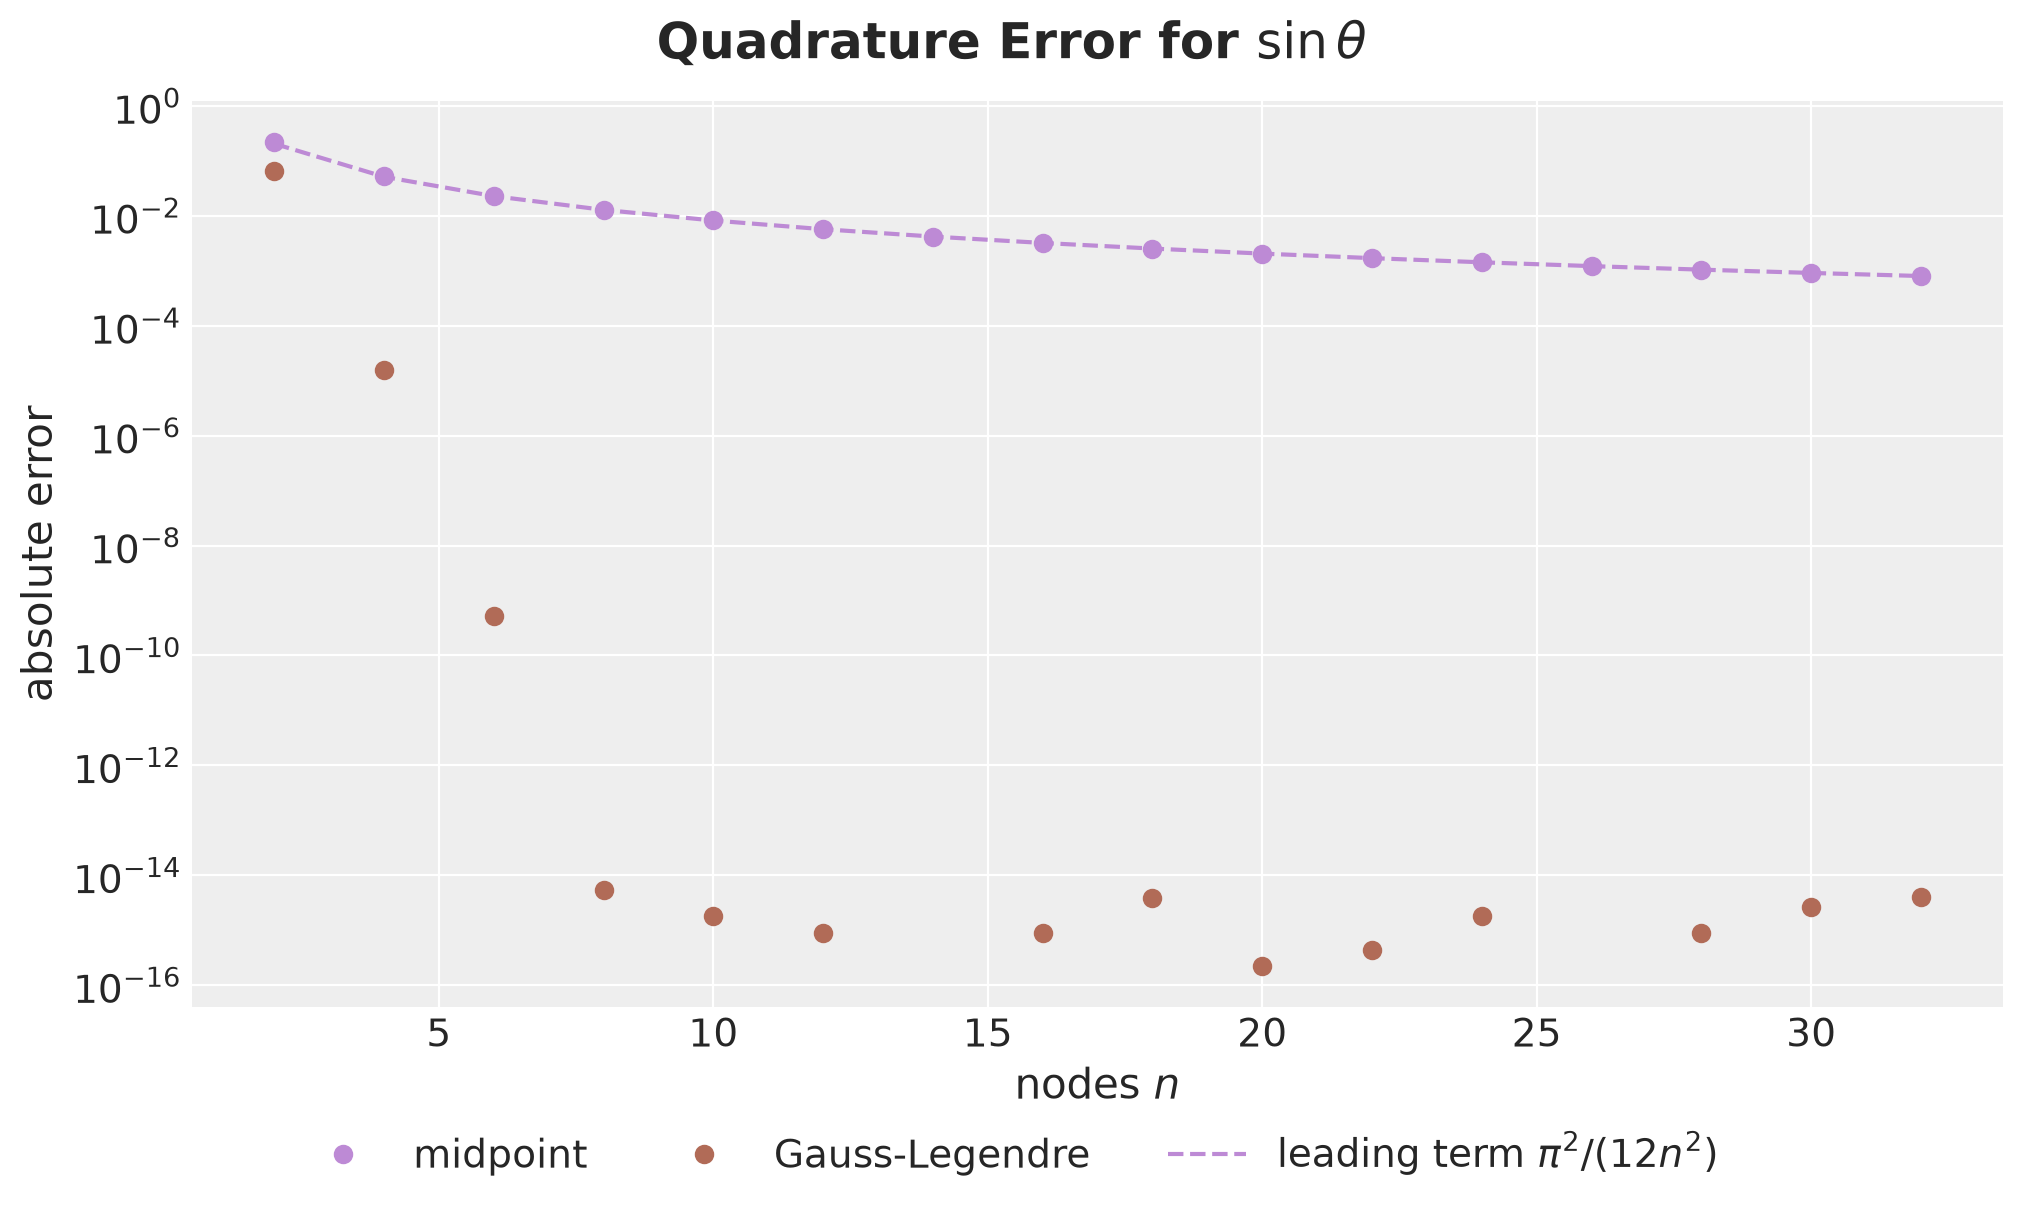

In [25]:
fig, ax = plt.subplots(layout="constrained")

for name, errors in sine_errors.items():
    ax.plot(
        N_NODES_SINE,
        errors,
        marker="o",
        linestyle="none",
        color=RULE_COLORS[name],
        label=name,
    )

leading_term = [torch.pi**2 / (12 * n_nodes**2) for n_nodes in N_NODES_SINE]
ax.plot(
    N_NODES_SINE,
    leading_term,
    color=RULE_COLORS["midpoint"],
    linestyle="--",
    label=r"leading term $\pi^2 / (12 n^2)$",
)
ax.set_yscale("log", nonpositive="mask")
ax.set(xlabel="nodes $n$", ylabel="absolute error")
fig.legend(loc="outside lower center", ncol=3)
fig.suptitle(r"Quadrature Error for $\sin\theta$", fontsize=18, fontweight="bold");

The two rules behave very differently near the poles:

- **Midpoint rule.** The error follows the leading term, and with $n = 32$ nodes it is still about $8.0 \times 10^{-4}$. Over the whole sphere the integral in $\varphi$ multiplies it by $2\pi$, which gives about $5.0 \times 10^{-3}$, far above the tolerance $10^{-5}$ of *Gauss-Bonnet Check*.
- **Gauss-Legendre rule.** The error falls geometrically, and it reaches round-off level with $n = 8$ nodes.

### Tensor-Product Nodes

Let's look at the tensor-product nodes of the sphere and the torus with $n = 8$ nodes per direction. The color and the area of a marker show its weight $\alpha_p \beta_q$, on one scale for both surfaces:

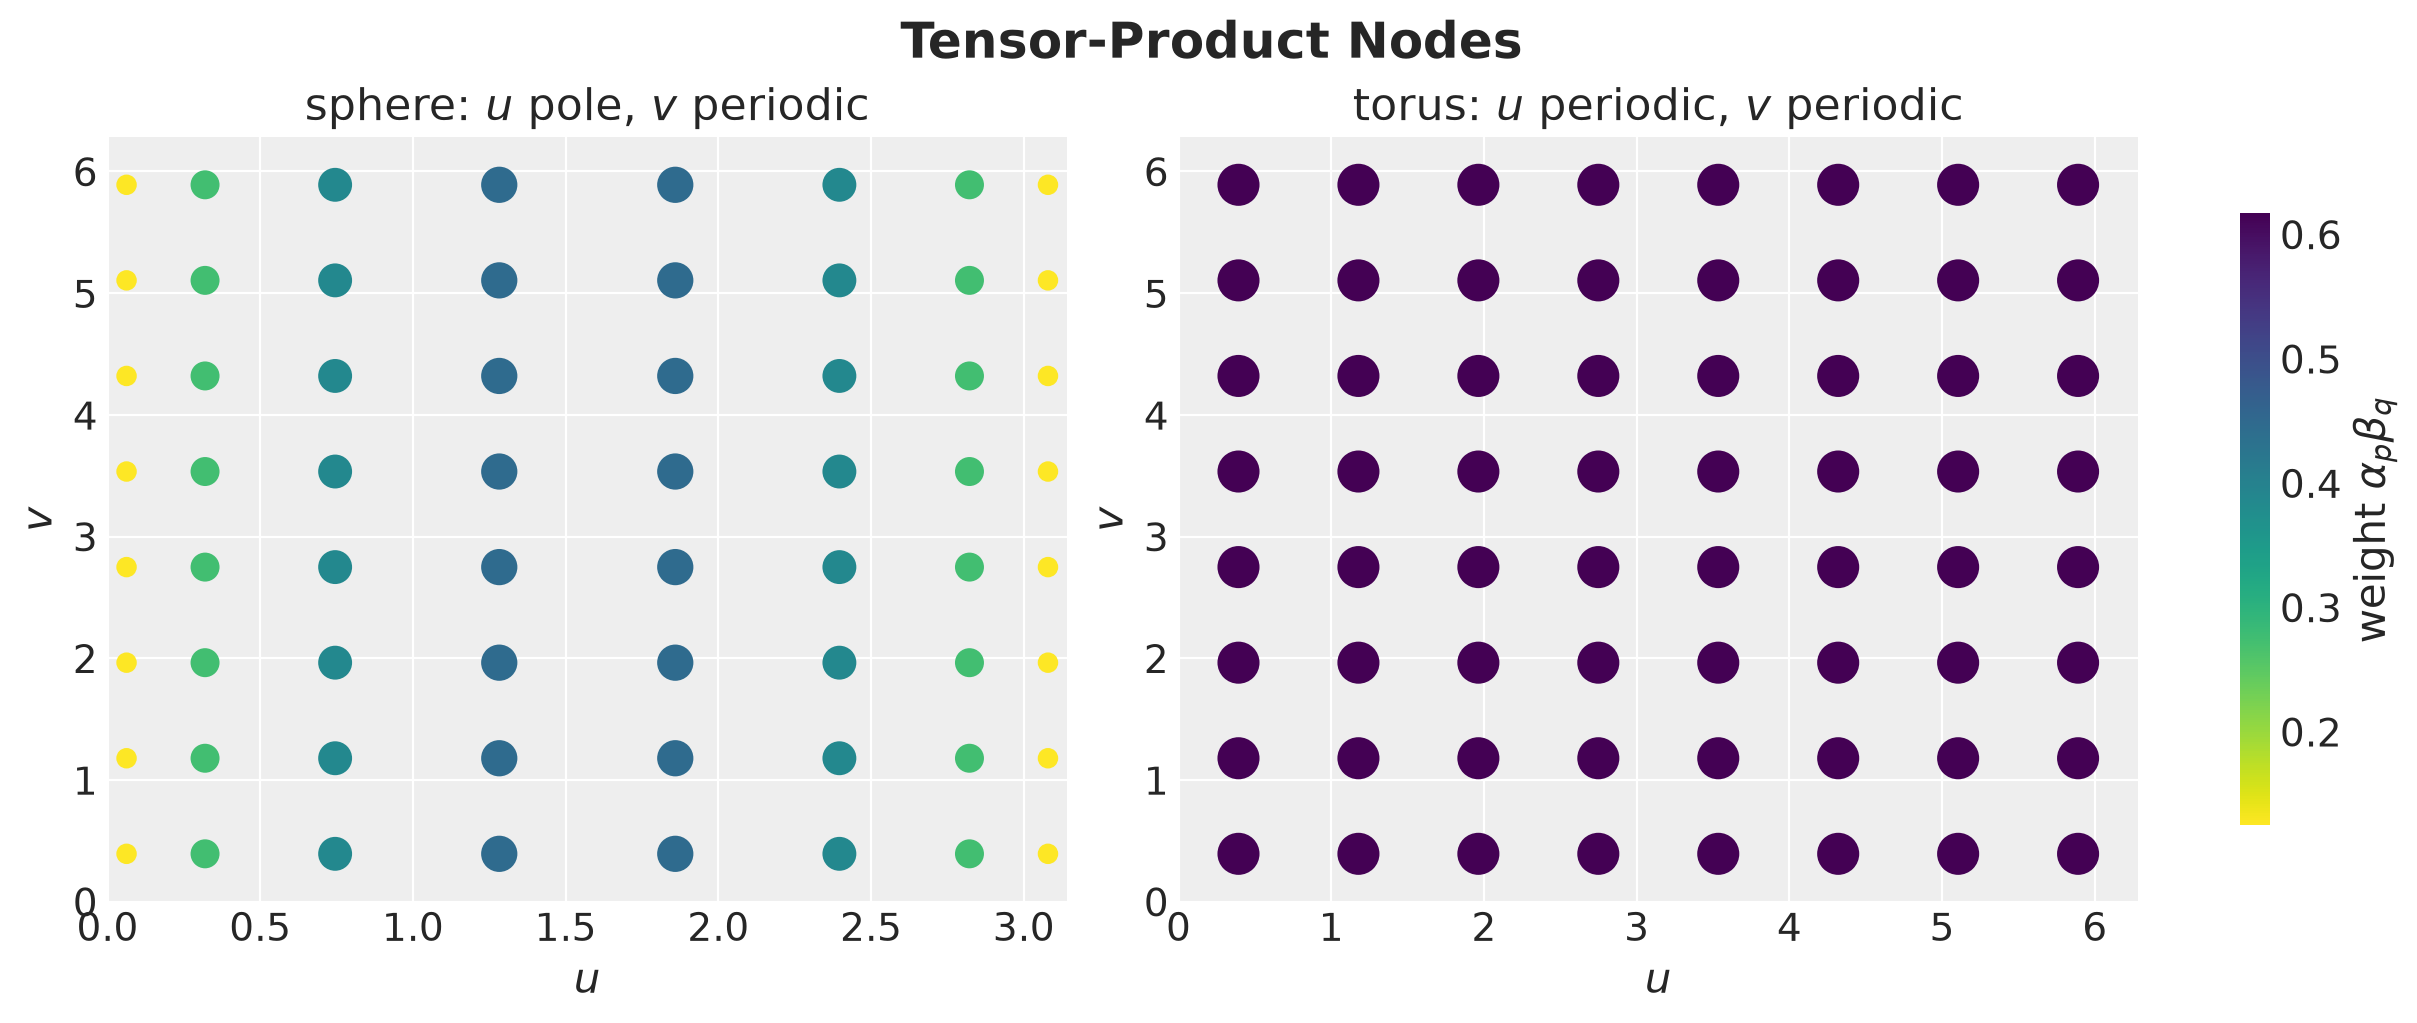

In [26]:
node_grids = {
    name: tensor_product_rule(surfaces[name], n_nodes=8) for name in ("sphere", "torus")
}
# One scale for both panels, so that equal weights get equal colors and sizes.
weight_norm = plt.Normalize(
    vmin=min(grid.weights.min().item() for grid in node_grids.values()),
    vmax=max(grid.weights.max().item() for grid in node_grids.values()),
)

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5), layout="constrained")

for ax, (name, grid) in zip(axes, node_grids.items(), strict=True):
    surface = surfaces[name]
    u, v = grid.points.unbind(dim=-1)
    scatter = ax.scatter(
        u,
        v,
        s=200 * grid.weights / weight_norm.vmax,
        c=grid.weights,
        cmap="viridis_r",
        norm=weight_norm,
    )
    u_closure, v_closure = surface.closures
    ax.set(
        title=f"{name}: $u$ {u_closure.name}, $v$ {v_closure.name}",
        xlim=surface.domain.u,
        ylim=surface.domain.v,
        xlabel="$u$",
        ylabel="$v$",
    )

fig.colorbar(scatter, ax=axes, shrink=0.8, label=r"weight $\alpha_p \beta_q$")
fig.suptitle("Tensor-Product Nodes", fontsize=18, fontweight="bold");

The weight of a grid point is the product of the weights of its two coordinates:

- **Sphere.** All nodes in a column share the Gauss-Legendre weight $\alpha_p$ of $u$, so the markers get smaller and lighter column by column toward the poles. Along $v$, the midpoint weights $\beta_q$ are all equal. The ellipsoid has the same domain and closures, so it has the same nodes.
- **Torus.** Both weights are constant, so every grid point has the same weight.

The weights of a panel add up to the area of its rectangle, because

$$
\sum_p \sum_q \alpha_p \beta_q = \left( \sum_p \alpha_p \right) \left( \sum_q \beta_q \right).
$$

The rectangle of the torus is twice as large ($2\pi \times 2\pi$ against $\pi \times 2\pi$), and so are its weights on average.

## References

- Crane, K. [Discrete Differential Geometry: An Applied Introduction](https://www.cs.cmu.edu/~kmcrane/Projects/DDG/). Carnegie Mellon University.
- do Carmo, M. P. [Differential Geometry of Curves and Surfaces](https://store.doverpublications.com/products/9780486806990). Second edition, Dover.
- geomstats. [Fix nested autodiff in pytorch backend (wrong riemann_tensor on ImmersedSet)](https://github.com/geomstats/geomstats/pull/2142). Pull request #2142.
- Miolane, N., et al. [Geomstats: A Python Package for Riemannian Geometry in Machine Learning](https://jmlr.org/papers/v21/19-027.html). Journal of Machine Learning Research 21(223), 2020.
- Trefethen, L. N. [Is Gauss Quadrature Better than Clenshaw-Curtis?](https://doi.org/10.1137/060659831). SIAM Review 50(1), 2008.
- Trefethen, L. N., and Weideman, J. A. C. [The Exponentially Convergent Trapezoidal Rule](https://doi.org/10.1137/130932132). SIAM Review 56(3), 2014.
- Weisstein, E. W. [Ellipsoid](https://mathworld.wolfram.com/Ellipsoid.html). MathWorld.
- Wikipedia. [Gauss-Bonnet theorem](https://en.wikipedia.org/wiki/Gauss%E2%80%93Bonnet_theorem), [Theorema Egregium](https://en.wikipedia.org/wiki/Theorema_Egregium), [Euler characteristic](https://en.wikipedia.org/wiki/Euler_characteristic), [Betti number](https://en.wikipedia.org/wiki/Betti_number), [Euler-Maclaurin formula](https://en.wikipedia.org/wiki/Euler%E2%80%93Maclaurin_formula), [Gauss-Legendre quadrature](https://en.wikipedia.org/wiki/Gauss%E2%80%93Legendre_quadrature).